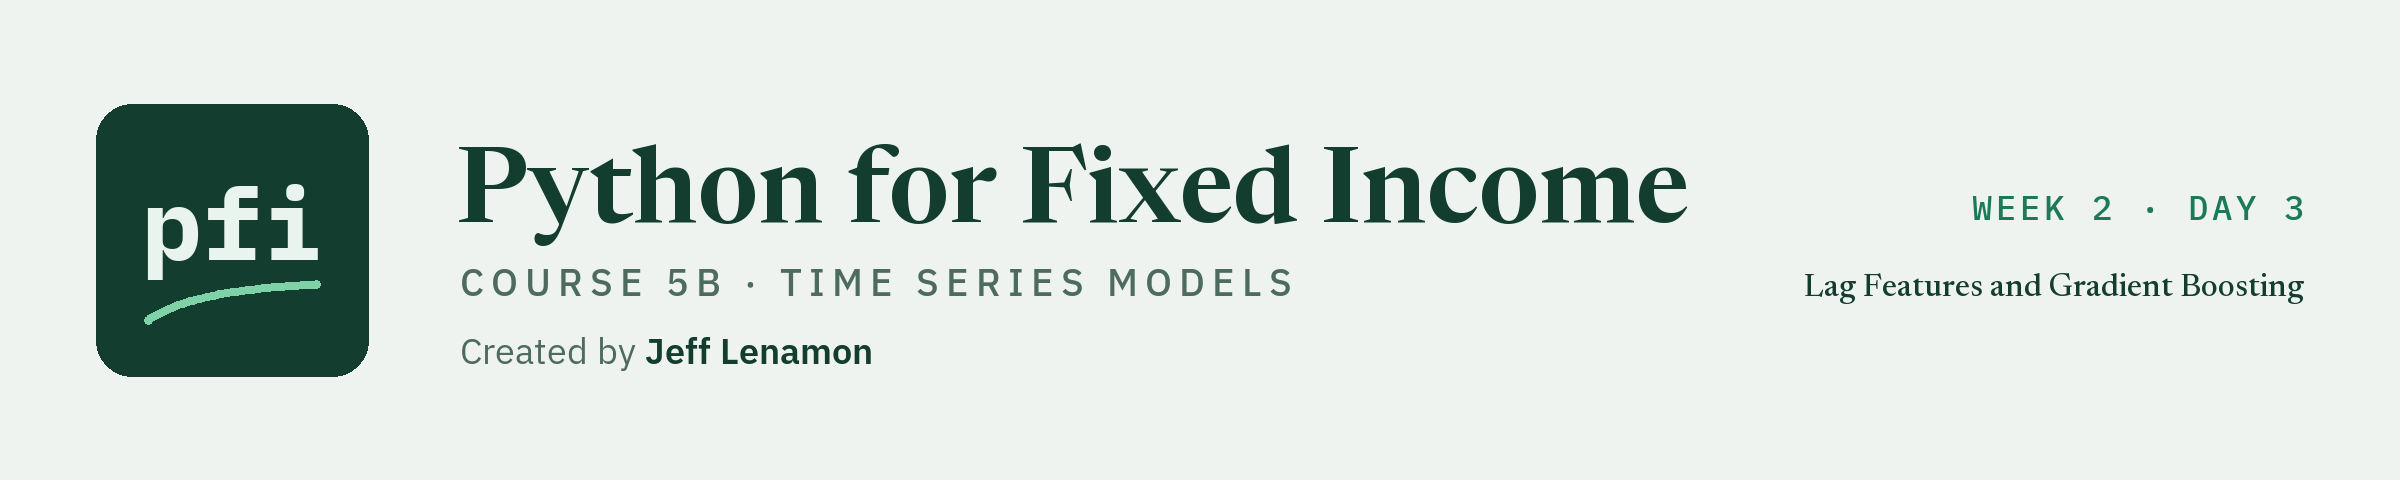

# Lag Features and Gradient Boosting

Week 2, Day 3. Turn a series' past into features without a leak, score LightGBM on them walk-forward against the last value, and read every setting that matters.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day3/08_lag_features_and_gradient_boosting.ipynb)

Days 5 to 7 gave a model one input, the series' own past, in one shape. A gradient-boosted tree model (LightGBM, Course 5 day 9) takes **many inputs at once** and finds its own shapes: it can use the last change, the average of the last five, the volatility of the last twenty, another series' last move, and the weekday, and it asks no question about linearity. The cost is a new place to go wrong. Every input is a column that **someone built**, and a column built from the wrong rows is a leak that scores beautifully and means nothing.

* **The task is in the past tense.** The target is the 10 Yr's change in bp on a date, from features built from the rows dated before it. Every fit is on earlier dates only, every score is on dates inside 2015-01-02 to 2022-12-30, and nothing is fitted for or reported at a later date. The held-out years stay closed until the capstone.
* **A model's output is a fitted change**, the model's value for that date. It is scored on day 2's five folds against the last value carried forward, day 5's AR(1), the drift, and day 6's smoothing, in the same table.
* **Features and folds.** Features are built on the whole development table in one pass, and each is checked, by a proof that changes every row from a date on, to use only earlier rows. That is the leakage rule of the course made into a function.
* **The honest finding comes first.** Day 5's finding held for every model without exception, and the finding here is the same, with a larger model: LightGBM on lags did not beat the last value. What is new is how it fails, what a leak looks like beside it, and a model that does find something, the size of the change.

Today you will:

1. Build lag features, and draw which rows feed each one.
2. Prove with a function that no feature uses its own date.
3. Show a leak on purpose, and see what it does to the score.
4. Score LightGBM walk-forward against the last value, the drift, the AR(1), and smoothing.
5. Read every setting of `LGBMRegressor`, sweep the ones that matter, and choose on the development folds.
6. Read permutation importance within folds, and use the same features for the size of the change against day 7's GARCH.

Q. Set up today's work folder: the thread settings, the seed, the data files, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05b_time_series/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, statsmodels, arch, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("arch", "arch"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05b_time_series/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "arch": "8.0.0", "scikit-learn": "1.9.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5b_08_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, arch 8.0.0, scikit-learn 1.9.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5b_08_t5aw7_mo, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv
SEED = 42


The setup cell is the same in every Course 5B notebook. `mlkit.py`, `tskit.py`, and its tests below are the files as day 7 left them, and `plotkit.py` is the series' chart helpers, unchanged. Today appends three functions to `tskit.py`. LightGBM is one of the libraries the setup cell checks.

Q. Write `mlkit.py`, Course 4's complete module, unchanged. `tskit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `tskit.py` and `test_tskit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile tskit.py
"""tskit: the time series pieces of Course 5B, written down and tested.

Written day by day in Python for Fixed Income, Course 5B: Time Series Models.

Conventions, the same in every function:
- A series is a pandas Series, and a frame a DataFrame, indexed by date: unique and ascending.
- Yields are in percent and changes in bp, as in the Treasury file; each docstring states its unit.
- A function that describes or repairs data never fills an earlier date from a later one unless its docstring
  says so in its first lines.
- A fitted value is for a date inside the file, from a model fitted on earlier dates only; it is never a
  statement about a date after the file ends.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # dated tables

import mlkit  # Course 4's module: its walk-forward splits and its past-only check are used from day 2


def _check_dated(index: pd.Index, name: str) -> None:
    """Stop unless the index is a DatetimeIndex that is not empty, unique, and ascending."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{name} must be indexed by date (a DatetimeIndex)")
    if len(index) == 0:
        raise ValueError(f"{name} is empty")
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError(f"{name} must have unique dates in ascending order")


def gap_report(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per column of a dated frame: where the series starts and ends, and where its values are blank.

    Input: frame, dated rows (a DatetimeIndex, unique and ascending), one column per series.
    Output: a DataFrame indexed by column name, with
      rows: the rows in the frame;
      first_valid, last_valid: the first and last dates that hold a value (NaT for a column with none);
      before_start: blank rows before first_valid (a series that had not started yet);
      blank_inside: blank cells from first_valid to last_valid (outages and gaps inside the series);
      after_end: blank rows after last_valid;
      longest_inside: the longest run of consecutive blank rows inside the series (0 when there is none).
    A date with no row at all (a market holiday) is not in the frame, so it is not counted here: compare the
    index with a calendar to find those.
    Raises ValueError for an empty frame or an index that is not dated, unique, and ascending.
    """
    _check_dated(frame.index, "frame")
    rows = []
    for column in frame.columns:
        blank = frame[column].isna().to_numpy()
        first, last = frame[column].first_valid_index(), frame[column].last_valid_index()
        if first is None:
            # no value at all: every row counts as before the start
            rows.append({"column": column, "rows": len(blank), "first_valid": pd.NaT, "last_valid": pd.NaT,
                         "before_start": len(blank), "blank_inside": 0, "after_end": 0, "longest_inside": 0})
            continue
        start, end = frame.index.get_loc(first), frame.index.get_loc(last)
        inside = blank[start:end + 1]
        runs = gap_runs(frame[column].iloc[start:end + 1]) if inside.any() else None
        rows.append({"column": column, "rows": len(blank), "first_valid": first, "last_valid": last,
                     "before_start": start, "blank_inside": int(inside.sum()), "after_end": len(blank) - 1 - end,
                     "longest_inside": int(runs["rows"].max()) if runs is not None else 0})
    return pd.DataFrame(rows).set_index("column")


def gap_runs(series: pd.Series) -> pd.DataFrame:
    """Every run of consecutive blank values in a dated series: its first and last dates and its length in rows.

    Input: series, values indexed by date (unique and ascending).
    Output: a DataFrame with one row per run, in date order, and columns
      start, end: the first and last dates of the run;
      rows: the number of blank rows in the run;
      kind: "before start" for a run on the first row (the series had not started), "after end" for a run that
      reaches the last row, and "inside" for every other run.
    With nothing blank, an empty DataFrame with the same columns. A run counts rows, not calendar days: a blank
    Friday and the blank Monday after it are one run of 2 rows.
    Raises ValueError for an empty series or an index that is not dated, unique, and ascending.
    """
    _check_dated(series.index, "series")
    blank = series.isna()
    # a new run number starts wherever blank switches between True and False
    run_number = (blank != blank.shift(fill_value=not blank.iloc[0])).cumsum()
    runs = []
    for _, run in series[blank].groupby(run_number[blank]):
        first, last = series.index.get_loc(run.index[0]), series.index.get_loc(run.index[-1])
        kind = "before start" if first == 0 else "after end" if last == len(series) - 1 else "inside"
        runs.append({"start": run.index[0], "end": run.index[-1], "rows": len(run), "kind": kind})
    return pd.DataFrame(runs, columns=["start", "end", "rows", "kind"])


def apply_corrections(frame: pd.DataFrame, corrections: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply a table of corrections to a dated frame; return the corrected copy and a log of every change.

    Inputs: frame, dated rows, one column per series; corrections, a DataFrame with the columns date, column,
    value, source: one row per cell to set. value may be NaN, to blank a value known to be wrong (DataFrame.update
    skips a NaN, so it can never blank a cell).
    Output: (corrected, log). corrected is a copy of frame; the input is not changed. log is a DataFrame with the
    columns date, column, old, new, source: one row per cell whose value changed, in the order of corrections.
    A correction that leaves a cell as it was (the same number, or blank to blank) is not a change and is not
    logged.
    Raises ValueError if corrections lacks one of its four columns, if a date or a column is not in frame, or if
    one cell is corrected twice.
    """
    _check_dated(frame.index, "frame")
    needed = ["date", "column", "value", "source"]
    missing = [name for name in needed if name not in corrections.columns]
    if missing:
        raise ValueError(f"corrections needs the columns {needed}; missing {missing}")
    dates = pd.DatetimeIndex(corrections["date"])
    unknown_dates = dates[~dates.isin(frame.index)]
    if len(unknown_dates):
        raise ValueError(f"dates not in frame: {[str(d.date()) for d in unknown_dates]}")
    unknown_columns = sorted(set(corrections["column"]) - set(frame.columns))
    if unknown_columns:
        raise ValueError(f"columns not in frame: {unknown_columns}")
    cells = list(zip(dates, corrections["column"]))
    if len(set(cells)) != len(cells):
        raise ValueError("a cell is corrected twice: one row per cell")
    corrected = frame.copy()
    log = []
    for (date, column), value, source in zip(cells, corrections["value"], corrections["source"]):
        old = corrected.at[date, column]
        # blank to blank, or the same number, is not a change
        if (pd.isna(old) and pd.isna(value)) or old == value:
            continue
        corrected.at[date, column] = value
        log.append({"date": date, "column": column, "old": old, "new": value, "source": source})
    return corrected, pd.DataFrame(log, columns=["date", "column", "old", "new", "source"])


NAIVE_KINDS = ("last", "mean", "drift")


def naive_values(series: pd.Series, kind: str, n_train: int | None = None) -> pd.Series:
    """The naive value for each date, built only from the dates before it.

    Input: series, a dated Series of levels (yields or spreads in bp); kind, one of
      "last": the value on the row before (the last value carried forward);
      "mean": the average of the values so far;
      "drift": the last value plus the average change so far;
    n_train, the rows of the training window, or None.
    Output: with n_train None, a Series on every date of the input, NaN where no earlier date exists (the first row
    for "last" and "mean", the first two rows for "drift"), each value using the dates before it. With n_train set,
    the Series for the dates from row n_train on, where "mean" and "drift" use the average level and the average
    change of the first n_train rows only, fixed for the whole test window, and "last" still uses the row before.
    Raises ValueError for an unknown kind, an input that is not dated and ascending, or an n_train outside 2 to
    one less than the rows.
    """
    _check_dated(series.index, "series")
    if kind not in NAIVE_KINDS:
        raise ValueError(f"kind must be one of {NAIVE_KINDS}, not {kind!r}")
    last = series.shift(1)
    if n_train is None:
        # expanding averages, shifted one row so a date never sees itself
        mean = series.expanding().mean().shift(1)
        change = series.diff().expanding().mean().shift(1)
        return {"last": last, "mean": mean, "drift": last + change}[kind]
    if not 2 <= n_train < len(series):
        raise ValueError(f"n_train must be from 2 to {len(series) - 1}, not {n_train}")
    train = series.iloc[:n_train]
    fixed = {"last": last, "mean": pd.Series(train.mean(), index=series.index),
             "drift": last + train.diff().mean()}[kind]
    return fixed.iloc[n_train:]


def _paired(actual, values) -> tuple[np.ndarray, np.ndarray]:
    """Two equal-length arrays with no NaN; anything else is a mistake to fix, not to hide."""
    a, v = np.asarray(actual, dtype=float), np.asarray(values, dtype=float)
    if a.shape != v.shape or a.ndim != 1 or len(a) == 0:
        raise ValueError(f"need two non-empty arrays of one length; got shapes {a.shape} and {v.shape}")
    if np.isnan(a).any() or np.isnan(v).any():
        raise ValueError("NaN in the scored values: drop those dates, or fill them on purpose, before scoring")
    return a, v


def mae(actual, values) -> float:
    """Mean absolute error: the average size of a miss, in the unit of the inputs (bp in this course)."""
    a, v = _paired(actual, values)
    return float(np.abs(a - v).mean())


def rmse(actual, values) -> float:
    """Root mean squared error, in the unit of the inputs. Squaring weights big misses more than MAE does."""
    a, v = _paired(actual, values)
    return float(np.sqrt(((a - v) ** 2).mean()))


def mase(actual, values, baseline) -> float:
    """MAE of `values` divided by the MAE of `baseline`, on the same dates (here: the last value carried forward).

    1.0 means as far from the actual values as the baseline; below 1.0 is closer. Raises ValueError if the
    baseline is exact on every date (a division by zero) or the inputs do not pair.
    """
    scale = mae(actual, baseline)
    if scale == 0:
        raise ValueError("the baseline has no error on these dates, so a ratio to it is undefined")
    return mae(actual, values) / scale


def walk_forward_score(series: pd.Series, fit_one, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a rule fold by fold, walk-forward, and check that it uses only the past.

    Inputs: series, a dated Series with no NaN (levels in bp); fit_one(history, n_train), a function that fits on
    history.iloc[:n_train] and returns one value per row from n_train to the end of history, the value for row t
    using only rows before t; splits, the (train_positions, test_positions) list of mlkit.walk_forward_splits
    with gap 0; check, whether to prove the past-only rule by removing later rows (default True).
    Output: (scores, values). scores has one row per fold: test_start, test_end, rows, mae, rmse, all against the
    actual series. values is a Series on the series' dates, NaN outside the test windows.
    The proof: the values for the first half of each test window plus one row are recomputed with every later row
    set to NaN; a value that moves used a later row, and AssertionError names its date.
    Raises ValueError for a series with NaN, a split with a gap, or a wrong number of values.
    """
    _check_dated(series.index, "series")
    if series.isna().any():
        raise ValueError("the series has blank dates: score only dates with a value (day 1)")
    values = pd.Series(np.nan, index=series.index)
    rows = []
    for number, (train, test) in enumerate(splits, start=1):
        mlkit.assert_past_only(series.index[train], series.index[test])
        n_train, end = len(train), int(test[-1]) + 1
        if int(test[0]) != n_train:
            raise ValueError("splits must have gap 0: the test window starts on the row after training")
        history = series.iloc[:end]
        found = np.asarray(fit_one(history, n_train), dtype=float)
        if found.shape != (end - n_train,):
            raise ValueError(f"fit_one returned {found.shape} values; the test window has {end - n_train} rows")
        if check:
            # rows from the halfway row on are removed: values up to and including that row may not move
            half = n_train + len(found) // 2
            removed = history.copy()
            removed.iloc[half:] = np.nan
            again = np.asarray(fit_one(removed, n_train), dtype=float)
            moved = np.flatnonzero(~np.isclose(found[:half - n_train + 1], again[:half - n_train + 1], equal_nan=True))
            if len(moved):
                raise AssertionError(f"fold {number}: the value for {history.index[n_train + moved[0]].date()} changed "
                                     "when later rows were removed, so it used a row that is not before its date")
        actual = series.iloc[test].to_numpy()
        values.iloc[test] = found
        rows.append({"fold": number, "test_start": series.index[test[0]], "test_end": series.index[test[-1]],
                     "rows": len(test), "mae": mae(actual, found), "rmse": rmse(actual, found)})
    return pd.DataFrame(rows).set_index("fold"), values


import warnings  # kpss_summary names the one warning it handles

from statsmodels.tools.sm_exceptions import InterpolationWarning  # statsmodels' ADF and KPSS tests
from statsmodels.tsa.stattools import adfuller, kpss


def _values(series: pd.Series, name: str) -> np.ndarray:
    """The values of a Series as floats, or ValueError: a test needs at least 20 values and no blank."""
    if not isinstance(series, pd.Series):
        raise ValueError(f"{name} must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 20:
        raise ValueError(f"{name} has {len(values)} values; a stationarity test needs at least 20")
    if np.isnan(values).any():
        raise ValueError(f"{name} has blank values: drop them first (the first change of a series is blank)")
    return values


def adf_summary(series: pd.Series, regression: str = "c", maxlag: int | None = None, autolag: str | None = "AIC") -> dict:
    """The augmented Dickey-Fuller test of a series, in a few named numbers.

    Null hypothesis: the series has a unit root (it wanders; it is not stationary). A small p-value rejects it.
    Inputs: series, values with no blank (levels or changes); regression, "c" (a constant), "ct" (a constant and a
    trend), or "n" (neither); maxlag, the most lagged changes to include (None lets statsmodels set it); autolag,
    the rule that picks the number of lagged changes up to maxlag ("AIC", "BIC", or None to use exactly maxlag).
    Output: a dict with statistic, p_value, lags_used, n_obs, critical_5pct (the 5 percent critical value), and
    rejects_unit_root (True when p_value is below 0.05).
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    result = adfuller(values, maxlag=maxlag, regression=regression, autolag=autolag, result_object=True)
    return {"statistic": float(result.statistic), "p_value": float(result.pvalue), "lags_used": int(result.lags),
            "n_obs": int(result.nobs), "critical_5pct": float(result.critical_values["5%"]),
            "rejects_unit_root": bool(result.pvalue < 0.05)}


def kpss_summary(series: pd.Series, regression: str = "c", nlags: str | int = "auto") -> dict:
    """The KPSS test of a series, in a few named numbers.

    Null hypothesis: the series is stationary (around a constant for "c", around a trend for "ct"). A small p-value
    rejects it, which is the opposite reading of the ADF test.
    Inputs: series, values with no blank; regression, "c" or "ct"; nlags, "auto" or the number of lags in the
    long-run variance estimate.
    Output: a dict with statistic, p_value, lags_used, critical_5pct, p_note, and rejects_stationarity (True when
    p_value is below 0.05). statsmodels interpolates p-values in a table that runs from 0.01 to 0.1, so a statistic
    outside the table gives 0.01 or 0.1 exactly; p_note then says "at most 0.01" or "at least 0.1", and "inside the
    table" otherwise.
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    # statsmodels warns when the statistic is outside its p-value table; p_note carries that information instead
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        result = kpss(values, regression=regression, nlags=nlags, result_object=True)
    p_value = float(result.pvalue)
    note = "at most 0.01" if p_value <= 0.01 else "at least 0.1" if p_value >= 0.1 else "inside the table"
    return {"statistic": float(result.statistic), "p_value": p_value, "lags_used": int(result.lags),
            "critical_5pct": float(result.critical_values["5%"]), "p_note": note, "rejects_stationarity": bool(p_value < 0.05)}


def acf_by_hand(series: pd.Series, lag: int) -> float:
    """The autocorrelation of a series at one lag, from the definition.

    The values' average is taken away; the autocorrelation at lag k is the sum, over every date that has a value k rows
    before it, of the product of the two deviations, divided by the sum of every deviation squared. It equals
    statsmodels' acf (adjusted=False), and differs a little from pandas' Series.autocorr, which takes the correlation
    of the two offset stretches.
    Inputs: series, values with no blank (changes in bp, say); lag, the rows between the two values (0 gives 1.0).
    Output: a float from -1 to 1.
    Raises ValueError for a series that is not a Series, has fewer than 3 values or a blank or no variation, or for a
    lag that is negative or not below the number of values.
    """
    if not isinstance(series, pd.Series):
        raise ValueError("series must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 3:
        raise ValueError(f"series has {len(values)} values; an autocorrelation needs at least 3")
    if np.isnan(values).any():
        raise ValueError("series has blank values: drop them first (the first change of a series is blank)")
    if not 0 <= lag < len(values):
        raise ValueError(f"lag must be from 0 to {len(values) - 1}; got {lag}")
    deviations = values - values.mean()
    total = float((deviations ** 2).sum())
    if total == 0:
        raise ValueError("series does not vary, so its autocorrelation is undefined")
    return float((deviations[lag:] * deviations[:len(values) - lag]).sum() / total)


from statsmodels.tools.sm_exceptions import EstimationWarning  # the one warning fit_arima handles
from statsmodels.tsa.arima.model import ARIMA


def fit_arima(values, order: tuple, trend: str = "c", require_convergence: bool = True, **settings):
    """Fit an ARIMA(p, d, q) by maximum likelihood to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (daily changes in bp, say); order, the tuple (p, d, q);
    trend, "n" (none), "c" (a constant), "t" (a time trend), or "ct"; require_convergence, whether to raise if the
    optimiser did not converge (the default) or return the results anyway, for a grid that records `converged`;
    settings, any other ARIMA setting by name (enforce_stationarity=False, say).
    Output: the fitted results; results.mle_retvals["converged"] says whether the optimiser converged.
    The array goes in without its dates on purpose: a series of trading days has no frequency, and statsmodels warns
    about a date index it cannot use. Two statsmodels messages are handled here and nowhere else: the optimiser's
    ConvergenceWarning is switched off through method_kwargs (the result says so instead), and the EstimationWarning
    "starting parameters replaced by zeros", which reports a fallback for mixed AR and MA orders, is caught.
    Raises ValueError for an order that is not three non-negative integers or values with a blank, and RuntimeError when
    require_convergence is True and the optimiser did not converge.
    """
    if len(order) != 3 or not all(isinstance(k, (int, np.integer)) and k >= 0 for k in order):
        raise ValueError(f"order must be three non-negative integers (p, d, q); got {order}")
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", EstimationWarning)
        results = ARIMA(array, order=order, trend=trend, **settings).fit(method_kwargs={"warn_convergence": False})
    if require_convergence and not results.mle_retvals["converged"]:
        raise RuntimeError(f"ARIMA{tuple(order)} did not converge on {len(array)} values: try a smaller order")
    return results


def arima_grid(values, max_p: int, max_q: int, trend: str = "c") -> pd.DataFrame:
    """The information criteria of every ARIMA(p, 0, q) with p up to max_p and q up to max_q, on one array.

    Input: values, as for fit_arima (a stationary series: a change, not a level); trend as for fit_arima.
    Output: a DataFrame with one row per (p, q), in order, and the columns p, q, aic, bic, converged. AIC is
    2k - 2 ln L and BIC is k ln(n) - 2 ln L, with k fitted parameters (including the variance) and L the likelihood:
    lower is better, and BIC charges more per parameter. A fit that did not converge keeps its row, with converged False.
    Only criteria of fits to the same values can be compared.
    """
    rows = []
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            results = fit_arima(values, (p, 0, q), trend=trend, require_convergence=False)
            rows.append({"p": p, "q": q, "aic": float(results.aic), "bic": float(results.bic),
                         "converged": bool(results.mle_retvals["converged"])})
    return pd.DataFrame(rows)


def walk_forward_arima(series: pd.Series, order: tuple, splits, trend: str = "c", check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an ARIMA's one-step values fold by fold, walk-forward, with the past-only proof of walk_forward_score.

    Inputs: series, a dated Series with no NaN, the series the ARIMA is fitted to (daily changes in bp for a stationary
    model, order (p, 0, q)); order, the tuple (p, d, q); splits, from mlkit.walk_forward_splits with gap 0 and positions in
    this series; trend, as for fit_arima; check, as for walk_forward_score.
    Each fold fits the ARIMA once, on its training rows only, then gives the model's value for every test row: the
    fitted model is run over the test rows with .append(..., refit=False), whose .predict gives the one-step value for each
    row from the rows before it. The parameters do not change inside a fold, and are refitted at the next fold.
    Output: (scores, values), as walk_forward_score returns them: the MAE and RMSE of each fold against the actual series,
    and the model's value for every test date.
    Raises what fit_arima and walk_forward_score raise (RuntimeError if a fold's fit does not converge).
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_arima(history.iloc[:n_train].to_numpy(), order, trend=trend)
        run = fitted[n_train].append(history.iloc[n_train:].to_numpy(), refit=False)
        return np.asarray(run.predict(start=n_train, end=len(history) - 1), dtype=float)

    return walk_forward_score(series, fit_one, splits, check=check)


from statsmodels.tsa.holtwinters import ExponentialSmoothing


def ewma(series: pd.Series, alpha: float) -> pd.Series:
    """The exponentially weighted moving average of a series, one recursive step per row.

    Input: series, a dated Series with no blank (levels in bp, or squared changes); alpha, the weight on the newest
    row, above 0 and up to 1 (1 gives the series back; a small alpha gives a slow average).
    Output: a Series on the same dates with s[0] = x[0] and s[t] = alpha x[t] + (1 - alpha) s[t-1], which is
    pandas' ewm(alpha=alpha, adjust=False).mean(). The value on a date uses that date's row and the rows before it;
    to use it as a value for a date, shift it down one row.
    Raises ValueError for an alpha outside (0, 1], an empty series, or a blank.
    """
    if not 0 < alpha <= 1:
        raise ValueError(f"alpha must be above 0 and at most 1, not {alpha}")
    values = series.to_numpy(dtype=float)
    if len(values) == 0 or np.isnan(values).any():
        raise ValueError("the series must have at least one row and no blank")
    smoothed = np.empty(len(values))
    smoothed[0] = values[0]
    for row in range(1, len(values)):
        smoothed[row] = alpha * values[row] + (1 - alpha) * smoothed[row - 1]
    return pd.Series(smoothed, index=series.index)


def smoothing_values(values, level0: float, alpha: float, trend0: float = 0.0, beta: float = 0.0, phi: float = 1.0) -> np.ndarray:
    """The one-step value of an exponential smoothing for every row, by the recursion, from fixed coefficients.

    Inputs: values, a one-dimensional array of levels in bp (a NaN stops the recursion from that row on); level0 and
    trend0, the state before the first row; alpha, beta, and phi, the weights on the newest level, on the newest trend,
    and the damping of the trend (1 means no damping). With trend0 = 0 and beta = 0 this is simple smoothing.
    Output: an array the length of values. Entry t is level[t-1] + phi x trend[t-1], the value for row t given only the
    rows before it, where level[t] = alpha x[t] + (1 - alpha)(level[t-1] + phi trend[t-1]) and
    trend[t] = beta (level[t] - level[t-1]) + (1 - beta) phi trend[t-1].
    """
    array = np.asarray(values, dtype=float)
    out = np.empty(len(array))
    level, trend = level0, trend0
    for row in range(len(array)):
        out[row] = level + phi * trend
        new_level = alpha * array[row] + (1 - alpha) * (level + phi * trend)
        trend = beta * (new_level - level) + (1 - beta) * phi * trend
        level = new_level
    return out


def fit_smoothing(values, trend: str | None = None, damped: bool = False, **settings):
    """Fit an exponential smoothing by least squares to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (levels in bp); trend, None for simple smoothing
    or "add" for Holt's linear trend; damped, whether the trend is damped (needs trend="add"); settings, any other
    ExponentialSmoothing setting by name (initialization_method, bounds). The starting level and trend are estimated
    along with the weights, from these values only.
    Output: the fitted results; results.params holds smoothing_level, smoothing_trend, damping_trend, initial_level,
    and initial_trend (nan for a part the model does not have).
    The array goes in without its dates for the reason fit_arima gives: a series of trading days has no frequency.
    Raises ValueError for values with a blank or fewer than 10 numbers.
    """
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    settings.setdefault("initialization_method", "estimated")
    return ExponentialSmoothing(array, trend=trend, damped_trend=damped, **settings).fit()


def walk_forward_smoothing(series: pd.Series, splits, trend: str | None = None, damped: bool = False,
                           check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an exponential smoothing's one-step values fold by fold, walk-forward, with walk_forward_score's proof.

    Inputs: series, a dated Series of levels in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0;
    trend and damped, as for fit_smoothing; check, as for walk_forward_score.
    Each fold fits the weights and the starting state on its training rows only, then runs the recursion
    (smoothing_values) over the training rows and on through the fold's rows with those weights held fixed: the value
    for a test row uses only the rows before it. The weights are fitted again at the next fold.
    Output: (scores, values), as walk_forward_score returns them. The level folds are day 2's, so the last value
    carried forward scores day 2's numbers on the same dates.
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_smoothing(history.iloc[:n_train].to_numpy(), trend=trend, damped=damped).params
        p = fitted[n_train]
        trended = trend is not None
        found = smoothing_values(history.to_numpy(), p["initial_level"], p["smoothing_level"],
                                 trend0=float(p["initial_trend"]) if trended else 0.0,
                                 beta=float(p["smoothing_trend"]) if trended else 0.0,
                                 phi=float(p["damping_trend"]) if damped else 1.0)
        return found[n_train:]

    return walk_forward_score(series, fit_one, splits, check=check)


from arch import arch_model

ABS_SCALE = float(np.sqrt(2 / np.pi))   # for a normal shock with standard deviation s, the average absolute shock is s x ABS_SCALE


def garch_half_life(alpha: float, beta: float) -> float:
    """The number of rows after which half of a volatility shock has faded, from a GARCH(1,1)'s alpha and beta.

    Inputs: alpha, the weight on the latest squared shock; beta, the weight on the variance before. Their sum is the
    persistence: the share of a variance gap that is still there one row later.
    Output: ln(0.5) / ln(alpha + beta) rows. At a persistence of 0.9 it is 6.6 rows; at 0.99 it is 69.
    Raises ValueError unless 0 < alpha + beta < 1: at 1 or above a shock never fades and the half-life does not exist.
    """
    persistence = alpha + beta
    if not 0 < persistence < 1:
        raise ValueError(f"alpha + beta must be above 0 and below 1 for a half-life; got {persistence:.4f}")
    return float(np.log(0.5) / np.log(persistence))


def fit_garch(changes, mean: str = "Constant", vol: str = "GARCH", p: int = 1, o: int = 0, q: int = 1,
              dist: str = "normal", **settings):
    """Fit a GARCH-family model by maximum likelihood to a plain array of changes and return arch's results.

    Inputs: changes, a one-dimensional array of at least 100 daily changes in bp with no blank (a change, never a level);
    mean, vol, p, o, q, dist, as for arch_model ("Constant" or "Zero" mean; "GARCH", "EGARCH", ...; lags of the squared
    shock, the asymmetry term, and the variance; "normal", "t", "skewt", "ged"); settings, any other arch_model setting.
    Output: the fitted results. For a GARCH(1,1), results.params is mu, omega, alpha[1], beta[1] (then nu for "t").
    The data are not rescaled (changes in bp are of the size arch expects), the optimiser's progress is not printed,
    and the fit raises if the optimiser did not converge.
    Raises ValueError for fewer than 100 values or a blank, and RuntimeError when the optimiser did not converge.
    """
    array = np.asarray(changes, dtype=float)
    if array.ndim != 1 or len(array) < 100 or np.isnan(array).any():
        raise ValueError("changes must be a one-dimensional array of at least 100 numbers with no blank")
    model = arch_model(array, mean=mean, vol=vol, p=p, o=o, q=q, dist=dist, rescale=False, **settings)
    results = model.fit(disp="off", update_freq=0)
    if results.convergence_flag != 0:
        raise RuntimeError(f"{vol}({p}, {o}, {q}) with a {dist} shock did not converge on {len(array)} values")
    return results


def garch_variance(changes, mu: float, omega: float, alpha: float, beta: float, variance0: float) -> np.ndarray:
    """The one-step variance of a GARCH(1,1) for every row, by the recursion, from fixed coefficients.

    Inputs: changes, a one-dimensional array in bp (a NaN stops the recursion from the next row on); mu, omega, alpha, and
    beta, the model's mean and variance coefficients; variance0, the variance for the first row.
    Output: an array the length of changes. Entry 0 is variance0, and entry t is
    omega + alpha (changes[t-1] - mu)^2 + beta x entry t-1: the variance for row t uses only the rows before it.
    """
    array = np.asarray(changes, dtype=float)
    out = np.empty(len(array))
    out[0] = variance0
    for row in range(1, len(array)):
        out[row] = omega + alpha * (array[row - 1] - mu) ** 2 + beta * out[row - 1]
    return out


def walk_forward_garch(changes: pd.Series, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a GARCH(1,1)'s one-step volatility fold by fold, walk-forward, against the size of each change.

    Inputs: changes, a dated Series of daily changes in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0
    and positions in this series; check, as for walk_forward_score.
    Each fold fits a normal GARCH(1,1) once, on its training rows only, then runs the variance recursion over the fold's
    rows from the last training row's variance, with the coefficients held fixed: the volatility for a test row uses
    only the rows before it. What is scored is the model's value for the absolute change, ABS_SCALE x the volatility,
    against the absolute change: MAE and RMSE by fold, as walk_forward_score computes them.
    Output: (scores, volatility): the scores table, and the fitted volatility in bp for every test date (NaN elsewhere).
    Raises what fit_garch and walk_forward_score raise.
    """
    fitted = {}

    def fit_one(history_abs: pd.Series, n_train: int) -> np.ndarray:
        # the signed changes with the same rows blank as the (possibly cut) history the proof hands over
        signed = changes.iloc[:len(history_abs)].to_numpy(dtype=float).copy()
        signed[np.isnan(history_abs.to_numpy())] = np.nan
        if n_train not in fitted:
            fitted[n_train] = fit_garch(changes.iloc[:n_train].to_numpy())
        result = fitted[n_train]
        mu, omega, alpha, beta = (float(v) for v in np.asarray(result.params)[:4])
        variance = garch_variance(signed[n_train - 1:], mu, omega, alpha, beta, float(result.conditional_volatility[-1]) ** 2)
        return ABS_SCALE * np.sqrt(variance[1:])

    scores, values = walk_forward_score(changes.abs(), fit_one, splits, check=check)
    return scores, values / ABS_SCALE

Writing tskit.py


In [5]:
%%writefile test_tskit.py
"""Tests for tskit, written day by day in Course 5B. Small seeded arrays only: no data file is read."""
import numpy as np
import pandas as pd
import pytest

import tskit


def dated_frame() -> pd.DataFrame:
    """Ten business days and two seeded columns of yields in percent. Column a starts on the third day and has a
    two-day blank inside (days 5 and 6, a Friday and a Monday); column b has a value on every day."""
    rng = np.random.default_rng(42)
    dates = pd.bdate_range("2024-01-01", periods=10)
    frame = pd.DataFrame({"a": rng.normal(4.0, 0.1, 10), "b": rng.normal(4.5, 0.1, 10)}, index=dates)
    frame.iloc[:2, 0] = np.nan
    frame.iloc[4:6, 0] = np.nan
    return frame


def test_gap_report_counts():
    report = tskit.gap_report(dated_frame())
    a, b = report.loc["a"], report.loc["b"]
    assert (a["rows"], a["before_start"], a["blank_inside"], a["after_end"], a["longest_inside"]) == (10, 2, 2, 0, 2)
    assert a["first_valid"] == pd.Timestamp("2024-01-03")
    assert (b["before_start"], b["blank_inside"], b["longest_inside"]) == (0, 0, 0)


def test_gap_report_refuses_unsorted_dates():
    frame = dated_frame()
    with pytest.raises(ValueError, match="ascending"):
        tskit.gap_report(frame.iloc[::-1])
    with pytest.raises(ValueError, match="DatetimeIndex"):
        tskit.gap_report(frame.reset_index(drop=True))


def test_gap_runs_kinds_and_lengths():
    runs = tskit.gap_runs(dated_frame()["a"])
    assert runs["rows"].tolist() == [2, 2]
    assert runs["kind"].tolist() == ["before start", "inside"]
    # a Friday and the Monday after it are one run of two rows
    assert runs["start"].iloc[1] == pd.Timestamp("2024-01-05") and runs["end"].iloc[1] == pd.Timestamp("2024-01-08")
    series = dated_frame()["b"]
    series.iloc[-3:] = np.nan
    assert tskit.gap_runs(series)["kind"].tolist() == ["after end"]


def test_gap_runs_none_blank():
    runs = tskit.gap_runs(dated_frame()["b"])
    assert runs.empty and runs.columns.tolist() == ["start", "end", "rows", "kind"]


def test_apply_corrections_logs_and_copies():
    frame = dated_frame()
    day = frame.index[3]
    corrections = pd.DataFrame({"date": [day, frame.index[4]], "column": ["b", "b"],
                                "value": [9.99, frame.at[frame.index[4], "b"]], "source": ["desk", "desk"]})
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert corrected.at[day, "b"] == 9.99 and frame.at[day, "b"] != 9.99
    # the second correction changes nothing, so only the first is logged
    assert log[["column", "new", "source"]].values.tolist() == [["b", 9.99, "desk"]]
    assert log["old"].iloc[0] == frame.at[day, "b"]


def test_apply_corrections_blanks_where_update_does_not():
    frame = dated_frame()
    day = frame.index[8]
    corrections = pd.DataFrame({"date": [day], "column": ["b"], "value": [np.nan], "source": ["desk"]})
    updated = frame.copy()
    updated.update(corrections.pivot(index="date", columns="column", values="value"))
    assert updated.at[day, "b"] == frame.at[day, "b"]
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert np.isnan(corrected.at[day, "b"]) and len(log) == 1 and np.isnan(log["new"].iloc[0])


def test_apply_corrections_refusals():
    frame = dated_frame()
    good = {"date": [frame.index[0]], "column": ["b"], "value": [4.0], "source": ["desk"]}
    with pytest.raises(ValueError, match="missing"):
        tskit.apply_corrections(frame, pd.DataFrame(good).drop(columns="source"))
    with pytest.raises(ValueError, match="dates not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"date": [pd.Timestamp("2024-01-06")]}))
    with pytest.raises(ValueError, match="columns not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"column": ["c"]}))
    with pytest.raises(ValueError, match="twice"):
        tskit.apply_corrections(frame, pd.concat([pd.DataFrame(good)] * 2))


def levels_series() -> pd.Series:
    """Five business days of a hand-checkable level series: 1, 2, 4, 7, 11 (the changes 1, 2, 3, 4)."""
    return pd.Series([1.0, 2.0, 4.0, 7.0, 11.0], index=pd.bdate_range("2024-01-01", periods=5))


def seeded_walk(rows: int = 40) -> pd.Series:
    """A seeded random walk in bp on business days."""
    rng = np.random.default_rng(42)
    return pd.Series(100.0 + rng.normal(0.0, 2.0, rows).cumsum(), index=pd.bdate_range("2024-01-01", periods=rows))


def last_value(history, n_train):
    return tskit.naive_values(history, "last", n_train).to_numpy()


def test_naive_values_use_only_earlier_dates():
    series = levels_series()
    last = tskit.naive_values(series, "last")
    mean = tskit.naive_values(series, "mean")
    drift = tskit.naive_values(series, "drift")
    assert np.isnan(last.iloc[0]) and last.iloc[1:].tolist() == [1.0, 2.0, 4.0, 7.0]
    assert np.isnan(mean.iloc[0]) and mean.iloc[1:].tolist() == pytest.approx([1.0, 1.5, 7 / 3, 3.5])
    # the last value plus the average change so far: 2 + 1, 4 + 1.5, 7 + 2
    assert drift.iloc[:2].isna().all() and drift.iloc[2:].tolist() == pytest.approx([3.0, 5.5, 9.0])
    # changing the last row moves no value dated before it
    other = series.copy()
    other.iloc[-1] = 99.0
    for kind in tskit.NAIVE_KINDS:
        assert tskit.naive_values(other, kind).iloc[:-1].equals(tskit.naive_values(series, kind).iloc[:-1])


def test_naive_values_with_a_training_window():
    series = levels_series()
    # the first 3 rows: mean level 7/3, average change 1.5, both fixed over the test window
    assert tskit.naive_values(series, "last", 3).tolist() == [4.0, 7.0]
    assert tskit.naive_values(series, "mean", 3).tolist() == pytest.approx([7 / 3, 7 / 3])
    assert tskit.naive_values(series, "drift", 3).tolist() == pytest.approx([5.5, 8.5])
    with pytest.raises(ValueError, match="kind"):
        tskit.naive_values(series, "median")
    with pytest.raises(ValueError, match="n_train"):
        tskit.naive_values(series, "last", 5)


def test_mae_rmse_mase_by_hand():
    actual, values, baseline = [1.0, 2.0, 3.0, 4.0], [1.0, 3.0, 3.0, 2.0], [2.0, 2.0, 5.0, 4.0]
    assert tskit.mae(actual, values) == 0.75
    assert tskit.rmse(actual, values) == pytest.approx(np.sqrt(5 / 4))
    # the baseline misses by 1, 0, 2, 0: MAE 0.75, so the ratio is exactly 1
    assert tskit.mase(actual, values, baseline) == 1.0
    assert tskit.mase(actual, actual, baseline) == 0.0
    assert tskit.mase(actual, baseline, values) == 1.0


def test_scoring_refuses_what_it_cannot_score():
    with pytest.raises(ValueError, match="NaN"):
        tskit.mae([1.0, np.nan], [1.0, 2.0])
    with pytest.raises(ValueError, match="one length"):
        tskit.rmse([1.0, 2.0], [1.0])
    with pytest.raises(ValueError, match="undefined"):
        tskit.mase([1.0, 2.0], [1.5, 2.5], [1.0, 2.0])


def test_walk_forward_score_last_value():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    scores, values = tskit.walk_forward_score(series, last_value, splits)
    assert len(scores) == 2 and scores["rows"].tolist() == [10, 10]
    # the last value's miss is the change itself
    changes = series.diff().abs()
    assert scores["mae"].iloc[0] == pytest.approx(changes.iloc[20:30].mean())
    assert values.iloc[:20].isna().all() and values.iloc[20:40].notna().all()
    assert values.iloc[25] == series.iloc[24]


def test_walk_forward_score_catches_a_later_row():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)

    def same_day(history, n_train):
        # the value for a date is the date's own value
        return history.iloc[n_train:].to_numpy()

    def whole_window_mean(history, n_train):
        # every value uses the mean of the whole test window, later rows included
        return np.full(len(history) - n_train, history.mean())

    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, same_day, splits)
    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, whole_window_mean, splits)
    # with the proof off, the cheat scores perfectly: that is why the proof is on by default
    scores, _ = tskit.walk_forward_score(series, same_day, splits, check=False)
    assert scores["mae"].max() == 0.0


def test_walk_forward_score_refusals():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="blank"):
        tskit.walk_forward_score(blank, last_value, splits)
    gapped = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=5, gap=2)
    with pytest.raises(ValueError, match="gap 0"):
        tskit.walk_forward_score(series, last_value, gapped)
    with pytest.raises(ValueError, match="values"):
        tskit.walk_forward_score(series, lambda history, n_train: np.zeros(3), splits)


def walk_and_noise() -> tuple[pd.Series, pd.Series]:
    """A seeded random walk and seeded white noise, 500 values each."""
    rng = np.random.default_rng(42)
    noise = pd.Series(rng.standard_normal(500))
    return noise.cumsum(), noise


def test_adf_summary_walk_and_noise():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.adf_summary(walk), tskit.adf_summary(noise)
    # a random walk has a unit root: the test does not reject it; noise does not: the test rejects
    assert not on_walk["rejects_unit_root"] and on_walk["p_value"] > 0.05
    assert on_noise["rejects_unit_root"] and on_noise["p_value"] < 0.001
    assert on_walk["statistic"] > on_walk["critical_5pct"] and on_noise["statistic"] < on_noise["critical_5pct"]


def test_adf_with_no_lags_is_a_regression():
    walk, _ = walk_and_noise()
    summary = tskit.adf_summary(walk, regression="c", maxlag=0, autolag=None)
    # the change on its lagged level and a constant: the statistic is the slope divided by its standard error
    y = walk.to_numpy()
    X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
    target = np.diff(y)
    beta, *_ = np.linalg.lstsq(X, target, rcond=None)
    resid = target - X @ beta
    se = np.sqrt(resid @ resid / (len(target) - 2) * np.linalg.inv(X.T @ X)[1, 1])
    assert summary["statistic"] == pytest.approx(beta[1] / se)
    assert summary["lags_used"] == 0 and summary["n_obs"] == len(target)


def test_kpss_summary_reads_the_other_way():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.kpss_summary(walk), tskit.kpss_summary(noise)
    # KPSS rejects stationarity for the walk and does not for the noise, the reverse of ADF's reading
    assert on_walk["rejects_stationarity"] and not on_noise["rejects_stationarity"]
    assert on_walk["p_note"] in ("at most 0.01", "inside the table") and on_noise["p_note"] == "at least 0.1"
    assert on_noise["p_value"] == 0.1


def test_summaries_refuse_bad_input():
    walk, _ = walk_and_noise()
    blank = walk.copy()
    blank.iloc[3] = np.nan
    for function in (tskit.adf_summary, tskit.kpss_summary):
        with pytest.raises(ValueError, match="blank"):
            function(blank)
        with pytest.raises(ValueError, match="at least 20"):
            function(walk.iloc[:10])
        with pytest.raises(ValueError, match="Series"):
            function(walk.to_numpy())


def test_acf_by_hand_on_five_numbers():
    series = pd.Series([1.0, 2.0, 3.0, 4.0, 5.0])
    # deviations -2 -1 0 1 2, their squares sum to 10: lag 1 gives 4 / 10, lag 2 gives -1 / 10
    assert tskit.acf_by_hand(series, 0) == 1.0
    assert tskit.acf_by_hand(series, 1) == pytest.approx(0.4)
    assert tskit.acf_by_hand(series, 2) == pytest.approx(-0.1)


def test_acf_by_hand_equals_statsmodels():
    from statsmodels.tsa.stattools import acf
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(300)
    series = pd.Series(shocks[1:] + 0.5 * shocks[:-1])
    library = acf(series, nlags=8, result_object=False)
    assert [tskit.acf_by_hand(series, lag) for lag in range(9)] == pytest.approx(library, abs=1e-12)
    # the same on a series with a date index: only the values matter
    dated = series.set_axis(pd.bdate_range("2024-01-01", periods=len(series)))
    assert tskit.acf_by_hand(dated, 3) == pytest.approx(library[3], abs=1e-12)


def test_acf_by_hand_refusals():
    series = pd.Series([1.0, 2.0, 4.0, 3.0, 5.0])
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, 5)
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, -1)
    with pytest.raises(ValueError, match="blank"):
        tskit.acf_by_hand(series.where(series != 4.0), 1)
    with pytest.raises(ValueError, match="does not vary"):
        tskit.acf_by_hand(pd.Series([2.0] * 5), 1)
    with pytest.raises(ValueError, match="at least 3"):
        tskit.acf_by_hand(series.iloc[:2], 1)
    with pytest.raises(ValueError, match="Series"):
        tskit.acf_by_hand(series.to_numpy(), 1)


def ar1_series(rows: int = 600, phi: float = 0.6) -> pd.Series:
    """A seeded AR(1) of daily changes in bp on business days."""
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(rows)
    values = np.zeros(rows)
    for row in range(1, rows):
        values[row] = phi * values[row - 1] + shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_fit_arima_recovers_an_ar1():
    results = tskit.fit_arima(ar1_series().to_numpy(), (1, 0, 0))
    constant, phi, variance = results.params
    # 600 seeded values: the coefficient is near the 0.6 that made them
    assert phi == pytest.approx(0.6, abs=0.1) and variance == pytest.approx(1.0, abs=0.25)
    assert results.mle_retvals["converged"]


def test_arima_grid_bic_picks_the_ar1():
    grid = tskit.arima_grid(ar1_series().to_numpy(), 2, 2)
    assert len(grid) == 9 and grid["converged"].all()
    best = grid.loc[grid["bic"].idxmin()]
    assert (best["p"], best["q"]) == (1, 0)


def test_walk_forward_arima_of_order_zero_is_the_training_mean():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    scores, values = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    for train, test in splits:
        assert values.iloc[test].to_numpy() == pytest.approx(series.iloc[train].mean(), abs=1e-4)
    assert len(scores) == 2 and scores["rows"].tolist() == [30, 30]


def test_walk_forward_arima_uses_only_the_past():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    _, values = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    # change every row from position 100 on: no value dated before position 100 may move
    other = series.copy()
    other.iloc[100:] = other.iloc[100:] + 5.0
    _, again = tskit.walk_forward_arima(other, (1, 0, 0), splits, check=False)
    assert values.iloc[:100].equals(again.iloc[:100])
    assert not values.iloc[100:110].equals(again.iloc[100:110])


def test_walk_forward_arima_beats_the_mean_on_an_ar1():
    series = ar1_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=300, test_size=100)
    model, _ = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    mean, _ = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    assert (model["mae"] < mean["mae"]).all()


def test_arima_refusals():
    values = ar1_series().to_numpy()
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, 0))
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, -1, 0))
    blank = values.copy()
    blank[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_arima(blank, (1, 0, 0))


def level_series(rows: int = 400) -> pd.Series:
    """A seeded level that wanders slowly, plus noise, in bp on business days."""
    rng = np.random.default_rng(7)
    level = 100.0 + np.cumsum(rng.normal(0.0, 0.3, rows))
    return pd.Series(level + rng.normal(0.0, 2.0, rows), index=pd.bdate_range("2020-01-01", periods=rows))


def test_ewma_equals_pandas_and_alpha_one_is_the_series():
    series = level_series()
    for alpha in (0.05, 0.3, 0.9):
        assert tskit.ewma(series, alpha).to_numpy() == pytest.approx(series.ewm(alpha=alpha, adjust=False).mean().to_numpy(), abs=1e-10)
    assert tskit.ewma(series, 1.0).equals(series)


def test_ewma_refusals():
    series = level_series(rows=20)
    for alpha in (0.0, -0.1, 1.5):
        with pytest.raises(ValueError, match="alpha"):
            tskit.ewma(series, alpha)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.ewma(blank, 0.5)


def test_smoothing_values_equal_statsmodels_fitted_values():
    values = level_series().to_numpy()
    for trend, damped in ((None, False), ("add", False), ("add", True)):
        results = tskit.fit_smoothing(values, trend=trend, damped=damped)
        p = results.params
        found = tskit.smoothing_values(values, p["initial_level"], p["smoothing_level"],
                                       trend0=float(p["initial_trend"]) if trend else 0.0,
                                       beta=float(p["smoothing_trend"]) if trend else 0.0,
                                       phi=float(p["damping_trend"]) if damped else 1.0)
        assert found == pytest.approx(results.fittedvalues, abs=1e-6)


def test_simple_smoothing_with_alpha_one_is_the_last_value():
    values = level_series(rows=50).to_numpy()
    found = tskit.smoothing_values(values, values[0], 1.0)
    assert found[1:] == pytest.approx(values[:-1], abs=1e-12)


def test_walk_forward_smoothing_uses_only_the_past():
    series = level_series(rows=200)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=100, test_size=40)
    _, values = tskit.walk_forward_smoothing(series, splits)
    # change every row from position 150 on: no value dated before position 150 may move
    other = series.copy()
    other.iloc[150:] = other.iloc[150:] + 20.0
    _, again = tskit.walk_forward_smoothing(other, splits, check=False)
    assert values.iloc[:150].equals(again.iloc[:150])
    assert not values.iloc[150:160].equals(again.iloc[150:160])


def test_smoothing_beats_the_last_value_on_a_noisy_level():
    series = level_series(rows=500)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=100)
    smooth, _ = tskit.walk_forward_smoothing(series, splits)
    last = [tskit.mae(series.iloc[test], series.shift(1).iloc[test]) for _, test in splits]
    assert (smooth["mae"].to_numpy() < np.array(last)).all()


def test_fit_smoothing_refusals():
    values = level_series().to_numpy()
    blank = values.copy()
    blank[5] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_smoothing(blank)
    with pytest.raises(ValueError, match="at least 10"):
        tskit.fit_smoothing(values[:5])


def garch_series(rows: int = 1500) -> pd.Series:
    """A seeded GARCH(1,1) of daily changes in bp: omega 0.1, alpha 0.1, beta 0.85, on business days."""
    rng = np.random.default_rng(11)
    shocks = rng.standard_normal(rows)
    variance = np.empty(rows)
    values = np.empty(rows)
    variance[0] = 0.1 / (1 - 0.95)
    values[0] = np.sqrt(variance[0]) * shocks[0]
    for row in range(1, rows):
        variance[row] = 0.1 + 0.1 * values[row - 1] ** 2 + 0.85 * variance[row - 1]
        values[row] = np.sqrt(variance[row]) * shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_garch_half_life_and_refusals():
    assert tskit.garch_half_life(0.05, 0.85) == pytest.approx(np.log(0.5) / np.log(0.9))
    # after that many rows, 0.9 to that power is one half
    assert 0.9 ** tskit.garch_half_life(0.05, 0.85) == pytest.approx(0.5)
    for alpha, beta in ((0.1, 0.9), (0.2, 0.9), (0.0, 0.0), (-0.2, 0.1)):
        with pytest.raises(ValueError, match="above 0 and below 1"):
            tskit.garch_half_life(alpha, beta)


def test_fit_garch_recovers_a_garch():
    results = tskit.fit_garch(garch_series().to_numpy())
    mu, omega, alpha, beta = results.params
    # 1,500 seeded values: the persistence is near the 0.95 that made them
    assert alpha + beta == pytest.approx(0.95, abs=0.04) and alpha == pytest.approx(0.1, abs=0.05)
    assert results.convergence_flag == 0


def test_garch_variance_equals_arch_conditional_variance():
    values = garch_series().to_numpy()
    results = tskit.fit_garch(values)
    mu, omega, alpha, beta = results.params
    again = tskit.garch_variance(values, mu, omega, alpha, beta, results.conditional_volatility[0] ** 2)
    assert again == pytest.approx(results.conditional_volatility ** 2, rel=1e-8)


def test_walk_forward_garch_uses_only_the_past():
    series = garch_series(rows=400)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=60)
    _, volatility = tskit.walk_forward_garch(series, splits)
    # change every row from position 270 on: no value dated before position 270 may move
    other = series.copy()
    other.iloc[270:] = other.iloc[270:] * 3.0
    _, again = tskit.walk_forward_garch(other, splits, check=False)
    assert volatility.iloc[:270].equals(again.iloc[:270])
    assert not volatility.iloc[270:280].equals(again.iloc[270:280])


def test_walk_forward_garch_is_closer_than_a_constant_size():
    series = garch_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=600, test_size=300)
    scores, volatility = tskit.walk_forward_garch(series, splits)
    size = series.abs()
    for number, (train, test) in enumerate(splits, start=1):
        constant = tskit.mae(size.iloc[test], np.full(len(test), size.iloc[train].mean()))
        assert scores.loc[number, "mae"] < constant
    assert volatility.iloc[:600].isna().all()


def test_fit_garch_refusals():
    values = garch_series().to_numpy()
    with pytest.raises(ValueError, match="at least 100"):
        tskit.fit_garch(values[:50])
    blank = values.copy()
    blank[7] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_garch(blank)

Writing test_tskit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import tskit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(tskit)

# the functions defined in tskit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(tskit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "tskit" and not name.startswith("_")]
print(f"tskit functions: {functions}")

tskit functions: ['gap_report', 'gap_runs', 'apply_corrections', 'naive_values', 'mae', 'rmse', 'mase', 'walk_forward_score', 'adf_summary', 'kpss_summary', 'acf_by_hand', 'fit_arima', 'arima_grid', 'walk_forward_arima', 'ewma', 'smoothing_values', 'fit_smoothing', 'walk_forward_smoothing', 'garch_half_life', 'fit_garch', 'garch_variance', 'walk_forward_garch']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


Q. Load the five series in bp on the development years, as days 2 to 7 did.

In [9]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# five series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "2 Yr": (development["2 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"five series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5, used by every later day: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
five series in bp: ['2 Yr', '10 Yr', '2s10s', 'IG', 'HY']; blank cells: 0


* The same cell: 2,001 development dates, five series, and no way to reach a held-out row.

Q. Make day 2's five folds for the changes, and for the levels (which day 6's smoothing uses), and the last value carried forward on the changes.

In [10]:
# day 2's folds on the levels, and on the changes (one row later: each fold's positions shift down by one)
changes = levels.diff().dropna()
level_splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
splits = [(train[1:] - 1, test - 1) for train, test in level_splits]
for number, (train, test) in enumerate(splits, start=1):
    mlkit.assert_past_only(changes.index[train], changes.index[test])
    print(f"fold {number}: fit on {len(train)} changes to {changes.index[train[-1]].date()}, "
          f"score {len(test)} from {changes.index[test[0]].date()} to {changes.index[test[-1]].date()}")

# the last value carried forward is a change of zero: its miss is the size of the change (day 5's baseline)
last_mae = pd.DataFrame({column: [changes[column].iloc[test].abs().mean() for _, test in splits] for column in changes.columns},
                        index=pd.Index(range(1, len(splits) + 1), name="fold"))
print(last_mae.mean().round(4).to_string())

fold 1: fit on 503 changes to 2017-01-05, score 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 755 changes to 2018-01-08, score 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1007 changes to 2019-01-11, score 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1259 changes to 2020-01-15, score 252 from 2020-01-16 to 2021-01-19
fold 5: fit on 1511 changes to 2021-01-19, score 252 from 2021-01-20 to 2022-01-19


2 Yr     2.1881
10 Yr    3.1937
2s10s    2.1548
IG       0.8017
HY       3.5018


* 5 folds, each fitted on the changes before it and scored on 252 dates: the first fits on 503 changes to 2017-01-05 and scores 2017-01-06 to 2018-01-08; the last scores 2021-01-20 to 2022-01-19. The last value's average MAE for the 10 Yr is 3.1937 bp, which is day 2's number to four decimals.

## 8.1 Lag Features, Built Without a Leak

**How it works.** A model that scores a date may use anything dated before it, and nothing dated on or after it. A **feature** is a number built from those earlier rows. A **lag** is the value some rows back. A **rolling statistic** summarises the last w rows: their mean, their standard deviation, the mean of their absolute values. The rule that keeps all of them honest is an order of operations: **shift first, then roll.** Shift the column down one row so each row holds the day before, and take the rolling window on the shifted column, so every window ends on the row before the date. A window taken on the unshifted column ends on the date itself, and the date's own change is inside its own feature. You control the lags, the window lengths, and whether to add other series' lags and calendar fields; what comes out is a table with one row per date and one column per feature, with missing values in the first rows where a window had too little history.

Q. Write `lag_features`. Read the docstring first.

In [11]:
%%writefile -a tskit.py


from lightgbm import LGBMRegressor


def lag_features(frame: pd.DataFrame, column: str, lags: list, windows: list, others: bool = True, calendar: bool = True) -> pd.DataFrame:
    """The features for scoring one column's value on each date, built only from the rows before that date.

    Inputs: frame, a dated DataFrame of daily changes in bp (one column per series, ascending dates, no NaN needed);
    column, the series to be scored; lags, whole numbers of 1 or more (lag 3 is the value three rows back); windows, whole
    numbers of 2 or more (rows in a rolling window); others, whether to add each other column's value one row back;
    calendar, whether to add the weekday (Monday is 0) and the month, which are known in advance for any date.
    Output: a DataFrame on the same dates with the columns "<column> lag L" for each lag; for each window w, "<column> mean w",
    "<column> sd w", and "<column> abs mean w" (the mean, the standard deviation, and the mean absolute value of the w rows
    before the date); "<other> lag 1" for each other column; then "weekday" and "month". The first max(lags, windows) rows have
    NaN where the history is too short.
    Every rolling statistic is taken on the column shifted one row down, so a window ends on the row before the date: shift first,
    then roll. A window taken before the shift would include the date's own value, which is the leak this module refuses.
    Raises ValueError for a column that is not in the frame, a lag below 1, or a window below 2.
    """
    if column not in frame.columns:
        raise ValueError(f"{column!r} is not a column of the frame: {list(frame.columns)}")
    if any(int(lag) != lag or lag < 1 for lag in lags):
        raise ValueError(f"lags must be whole numbers of 1 or more (a lag of 0 is the row itself); got {list(lags)}")
    if any(int(window) != window or window < 2 for window in windows):
        raise ValueError(f"windows must be whole numbers of 2 or more; got {list(windows)}")
    series = frame[column]
    features = {f"{column} lag {lag}": series.shift(lag) for lag in lags}
    past = series.shift(1)
    for window in windows:
        features[f"{column} mean {window}"] = past.rolling(window).mean()
        features[f"{column} sd {window}"] = past.rolling(window).std()
        features[f"{column} abs mean {window}"] = past.abs().rolling(window).mean()
    if others:
        for other in frame.columns:
            if other != column:
                features[f"{other} lag 1"] = frame[other].shift(1)
    if calendar:
        features["weekday"] = pd.Series(frame.index.dayofweek, index=frame.index)
        features["month"] = pd.Series(frame.index.month, index=frame.index)
    return pd.DataFrame(features)

Appending to tskit.py


* Every rolling statistic is taken on `past = series.shift(1)`. That one line is the whole discipline of the function.
* The calendar fields, the weekday and the month, are known in advance for any date, so they carry no leak. The other series' columns enter as their value one row back.
* It refuses a lag below 1 (a lag of 0 is the row itself), a window below 2, and a column the frame does not have.

Q. Write its first tests: the columns and values on a seeded frame, and the refusals.

In [12]:
%%writefile -a test_tskit.py


def lag_frame(rows: int = 700) -> pd.DataFrame:
    """Two seeded series of daily changes in bp on business days: a, with memory (AR(1), phi 0.6), and b, noise."""
    rng = np.random.default_rng(5)
    shocks = rng.standard_normal(rows)
    a = np.zeros(rows)
    for row in range(1, rows):
        a[row] = 0.6 * a[row - 1] + shocks[row]
    return pd.DataFrame({"a": a, "b": rng.standard_normal(rows)}, index=pd.bdate_range("2020-01-01", periods=rows))


def test_lag_features_columns_and_values():
    frame = lag_frame()
    features = tskit.lag_features(frame, "a", [1, 3], [5])
    assert list(features.columns) == ["a lag 1", "a lag 3", "a mean 5", "a sd 5", "a abs mean 5", "b lag 1", "weekday", "month"]
    assert features["a lag 3"].iloc[10] == frame["a"].iloc[7]
    # the window of 5 ends on the row before the date: rows 5 to 9 for row 10
    assert features["a mean 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].mean())
    assert features["a sd 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].std())
    assert features["a abs mean 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].abs().mean())
    assert features["weekday"].iloc[0] == 2 and features["month"].iloc[0] == 1     # 2020-01-01 was a Wednesday
    assert features["a mean 5"].iloc[:5].isna().all() and features["a mean 5"].iloc[5:].notna().all()


def test_lag_features_refusals():
    frame = lag_frame(rows=50)
    with pytest.raises(ValueError, match="not a column"):
        tskit.lag_features(frame, "z", [1], [5])
    with pytest.raises(ValueError, match="1 or more"):
        tskit.lag_features(frame, "a", [0, 1], [5])
    with pytest.raises(ValueError, match="2 or more"):
        tskit.lag_features(frame, "a", [1], [1])

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [13]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"lag_features in tskit: {hasattr(tskit, 'lag_features')}")

lag_features in tskit: True


In [14]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........................................                               [100%]
42 passed in 5.70s



* `42 passed`: day 7's 40 and two new ones.

Q. Build the features of the 10 Yr's change and read four dates side by side.

In [15]:
# every feature of the 10 Yr's change on a date, built from the rows before it: lags 1, 2, and 5, windows of 5 and 20, the other series, the calendar
lags, windows = [1, 2, 5], [5, 20]
features = tskit.lag_features(changes, "10 Yr", lags, windows)
target = changes["10 Yr"]
print(f"{features.shape[1]} features: {', '.join(features.columns)}")
print(f"rows with a missing feature: {int(features.isna().any(axis=1).sum())} (the first {max(lags + windows)}, where the longest window had too little history)")

# four dates side by side, so a row of features can be read
sample_dates = features.index[[20, 21, 22, 23]]
feature_table = features.loc[sample_dates].T.round(2)
feature_table.columns = [str(date.date()) for date in sample_dates]
feature_table.index.name = "feature"
print(feature_table.to_string())

plotkit.styled(feature_table, [], "The features of four dates: lags 1, 2, and 5, windows of 5 and 20, the other series' last changes, and the calendar", fmt="{:.2f}")

15 features: 10 Yr lag 1, 10 Yr lag 2, 10 Yr lag 5, 10 Yr mean 5, 10 Yr sd 5, 10 Yr abs mean 5, 10 Yr mean 20, 10 Yr sd 20, 10 Yr abs mean 20, 2 Yr lag 1, 2s10s lag 1, IG lag 1, HY lag 1, weekday, month
rows with a missing feature: 20 (the first 20, where the longest window had too little history)
                   2015-02-03  2015-02-04  2015-02-05  2015-02-06
feature                                                          
10 Yr lag 1              0.00       11.00        2.00        2.00
10 Yr lag 2             -9.00        0.00       11.00        2.00
10 Yr lag 5              0.00      -10.00        4.00       -9.00
10 Yr mean 5            -3.00       -0.80        1.60        1.20
10 Yr sd 5               6.16        8.87        7.23        7.12
10 Yr abs mean 5         4.60        6.80        5.20        4.80
10 Yr mean 20           -2.20       -1.25       -0.80       -0.65
10 Yr sd 20              5.56        6.11        6.00        6.03
10 Yr abs mean 20        4.90        5.05

,2015-02-03,2015-02-04,2015-02-05,2015-02-06
feature,,,,
10 Yr lag 1,0.00,11.00,2.00,2.00
10 Yr lag 2,-9.00,0.00,11.00,2.00
10 Yr lag 5,0.00,-10.00,4.00,-9.00
10 Yr mean 5,-3.00,-0.80,1.60,1.20
10 Yr sd 5,6.16,8.87,7.23,7.12
10 Yr abs mean 5,4.60,6.80,5.20,4.80
10 Yr mean 20,-2.20,-1.25,-0.80,-0.65
10 Yr sd 20,5.56,6.11,6.00,6.03
10 Yr abs mean 20,4.90,5.05,4.80,4.85


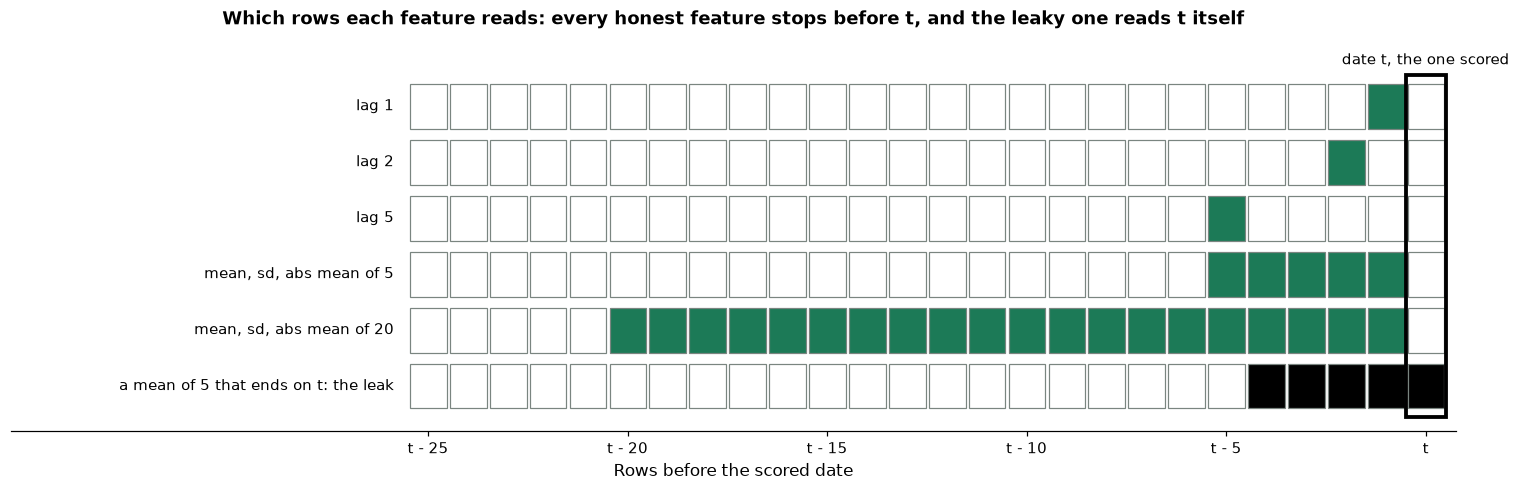

In [16]:
# for one scored date t, which rows feed each feature: green cells are used, the cell at t is the date itself
fig, ax = plt.subplots(figsize=(14, 4.6))
span, t_row = 26, 25
feature_rows = [("lag 1", [t_row - 1]), ("lag 2", [t_row - 2]), ("lag 5", [t_row - 5]), ("mean, sd, abs mean of 5", list(range(t_row - 5, t_row))),
                ("mean, sd, abs mean of 20", list(range(t_row - 20, t_row))), ("a mean of 5 that ends on t: the leak", list(range(t_row - 4, t_row + 1)))]
for line, (label, used) in enumerate(feature_rows):
    y = len(feature_rows) - 1 - line
    for cell in range(span):
        leak_row = line == len(feature_rows) - 1
        color = ("black" if leak_row else plotkit.GREEN) if cell in used else "white"
        ax.add_patch(plt.Rectangle((cell, y), 0.92, 0.8, facecolor=color, edgecolor=plotkit.GREY, linewidth=0.8))
    ax.text(-0.4, y + 0.4, label, ha="right", va="center", fontsize=10)
ax.add_patch(plt.Rectangle((t_row - 0.04, -0.15), 1.0, len(feature_rows) + 0.1, fill=False, edgecolor="black", linewidth=2.5))
ax.text(t_row + 0.45, len(feature_rows) + 0.15, "date t, the one scored", ha="center", fontsize=10)
ax.set_xlim(-10, span + 0.2)
ax.set_ylim(-0.4, len(feature_rows) + 0.7)
ax.set_xticks([0.45, 5.45, 10.45, 15.45, 20.45, 25.45], [f"t - 25", "t - 20", "t - 15", "t - 10", "t - 5", "t"])
ax.set_yticks([])
ax.set_xlabel("Rows before the scored date")
ax.set_title("Which rows each feature reads: every honest feature stops before t, and the leaky one reads t itself")
ax.grid(False)
for side in ("left", "top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

* 15 features: three lags, three statistics for each of two windows, the four other series' last changes, and two calendar fields. The first 20 rows have a missing feature, where the 20-row window had too little history; the model fits on the rows that have all of them.
* How to read the picture: each row of cells is one feature, and the green cells are the rows it reads. Every honest feature stops one cell before the date t. The black row at the bottom is a mean of five that ends on t, a leak, which section 8.3 builds on purpose.

## 8.2 LightGBM Walk-Forward

**How it works.** Gradient boosting builds a model one small tree at a time. The first tree fits the target roughly. The next fits what the first one missed, and the one after fits what is still missed, and each new tree's correction is scaled down by a **learning rate** before it is added. The fit stops after a set number of trees. Each tree splits the rows by asking a question of one feature (is the 5-row standard deviation above 6 bp?) and gives each leaf a value. You control the number of trees, the learning rate, the number of leaves per tree, and the fewest rows in a leaf; what comes out is a model that gives a value for any row of features. Walk-forward scoring fits it once per fold, on that fold's training rows, and gives a value for each of the fold's test rows from that row's features.

Q. Add `walk_forward_lgbm`.

In [17]:
%%writefile -a tskit.py


def walk_forward_lgbm(features: pd.DataFrame, target: pd.Series, splits, check: bool = True, **settings) -> tuple[pd.DataFrame, pd.Series]:
    """Score LightGBM's value for each test date fold by fold, walk-forward, with walk_forward_score's proof.

    Inputs: features, a DataFrame on the same dates as target, built only from earlier rows (lag_features); target, a dated
    Series with no NaN (daily changes in bp, or their absolute values); splits, from mlkit.walk_forward_splits with gap 0 and
    positions in this series; check, as for walk_forward_score; settings, any LGBMRegressor setting by name (n_estimators=100,
    learning_rate=0.03, objective="l1", ...). random_state is 42, n_jobs is 1, and verbose is -1 unless a setting says otherwise.
    Each fold fits one LGBMRegressor on its training rows only, leaving out the rows whose features are NaN (the first rows,
    where a window was too short), then gives its value for every test row from that row's features. The next fold is fitted
    again on a longer window.
    Output: (scores, values), as walk_forward_score returns them.
    """
    params = {"random_state": 42, "n_jobs": 1, "verbose": -1} | settings
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the model sees training rows only, so the fit is shared by the proof's second run
        if n_train not in fitted:
            train_features, train_target = features.iloc[:n_train], target.iloc[:n_train]
            complete = train_features.notna().all(axis=1).to_numpy()
            fitted[n_train] = LGBMRegressor(**params).fit(train_features[complete], train_target[complete])
        return np.asarray(fitted[n_train].predict(features.iloc[n_train:len(history)]), dtype=float)

    return walk_forward_score(target, fit_one, splits, check=check)

Appending to tskit.py


* It is `walk_forward_score` with a rule: `fit_one` fits one `LGBMRegressor` on the training rows (leaving out the rows whose features are missing), shares the fit with the proof's second run, and gives the values for the test rows. The seed, one thread, and a quiet log are the defaults, and any setting can be passed by name.
* The proof in `walk_forward_score` checks that the values do not depend on later targets. It does not check the features: that is the next section's proof. Both are needed.

Q. Write the tests: LightGBM beats the training mean on a seeded series with memory, and no value before a changed row moves.

In [18]:
%%writefile -a test_tskit.py


def test_walk_forward_lgbm_beats_the_mean_on_an_ar1():
    frame = lag_frame()
    features = tskit.lag_features(frame, "a", [1, 2], [5], others=False, calendar=False)
    splits = tskit.mlkit.walk_forward_splits(frame.index, min_train=300, test_size=100)
    scores, values = tskit.walk_forward_lgbm(features, frame["a"], splits, n_estimators=60, learning_rate=0.05, num_leaves=4)
    mean_miss = [tskit.mae(frame["a"].iloc[test], np.full(len(test), frame["a"].iloc[train].mean())) for train, test in splits]
    assert (scores["mae"].to_numpy() < np.array(mean_miss)).all()
    assert values.iloc[:300].isna().all()


def test_walk_forward_lgbm_uses_only_the_past():
    frame = lag_frame(rows=500)
    build = lambda f: tskit.lag_features(f, "a", [1, 2], [5])
    splits = tskit.mlkit.walk_forward_splits(frame.index, min_train=250, test_size=60)
    _, values = tskit.walk_forward_lgbm(build(frame), frame["a"], splits, n_estimators=30)
    # change every row from position 400 on, in the features and the target: no value dated before 400 may move
    other = frame.copy()
    other.iloc[400:] = other.iloc[400:] * 3.0
    _, again = tskit.walk_forward_lgbm(build(other), other["a"], splits, check=False, n_estimators=30)
    assert values.iloc[:400].equals(again.iloc[:400])
    assert not values.iloc[400:410].equals(again.iloc[400:410])

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [19]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"walk_forward_lgbm in tskit: {hasattr(tskit, 'walk_forward_lgbm')}")

walk_forward_lgbm in tskit: True


In [20]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

............................................                             [100%]
44 passed in 5.65s



* `44 passed`: day 7's 40, two tests for `lag_features`, and two new ones. On a series that has memory, built to have it, LightGBM beats the mean: the code can win when the data allow.

## 8.3 Proving Nothing Leaks, and a Leak on Purpose

**How it works.** A leak is not an error message. It is a column that happens to contain the answer, and the score that follows is better, and false. The test for it is mechanical: change every row of the data from a date t on, build the features again, and look at the features dated up to t. An honest feature at date t reads only the rows before t, so changing the rows from t on cannot move it. A leaky feature moves. You control the dates tested; what comes out is silence if every feature passes, and an error naming the feature and the date if one does not.

Q. Add `assert_features_past_only`, and its tests.

In [21]:
%%writefile -a tskit.py


def assert_features_past_only(build, frame: pd.DataFrame, rows) -> None:
    """Prove that the features built by `build` on a date use nothing from that date or later.

    Inputs: build, a function from a frame to a feature DataFrame on the same dates (for example
    lambda f: lag_features(f, "10 Yr", [1, 2], [5])); frame, the dated DataFrame of values; rows, the positions to test.
    For each position t, every row of the frame from t on is changed (1,000 is added to every value), and the features are
    built again: the features dated up to and including t must not move. A feature that moves used the row at t or later.
    Output: None when every tested position passes.
    Raises AssertionError naming the feature and the date, and ValueError for a position outside the frame.
    """
    base = build(frame)
    for position in rows:
        if not 0 < position < len(frame):
            raise ValueError(f"position {position} is outside the frame of {len(frame)} rows")
        changed = frame.copy()
        changed.iloc[position:] = changed.iloc[position:] + 1_000.0
        again = build(changed)
        for name in base.columns:
            same = base[name].iloc[:position + 1].equals(again[name].iloc[:position + 1])
            if not same:
                moved = (base[name].iloc[:position + 1] != again[name].iloc[:position + 1]) & ~(base[name].iloc[:position + 1].isna() & again[name].iloc[:position + 1].isna())
                first = moved.idxmax()
                raise AssertionError(f"the feature {name!r} dated {first.date()} changed when the rows from {frame.index[position].date()} on changed, "
                                     "so it uses a row that is not before its date")

Appending to tskit.py


In [22]:
%%writefile -a test_tskit.py


def test_lag_features_use_only_the_past():
    frame = lag_frame()
    tskit.assert_features_past_only(lambda f: tskit.lag_features(f, "a", [1, 2, 5], [5, 20]), frame, [30, 200, 650])


def test_assert_features_past_only_catches_a_leak():
    frame = lag_frame()

    def leaky(f):
        features = tskit.lag_features(f, "a", [1], [5])
        # a window that ends on the date itself
        features["leak"] = f["a"].rolling(5).mean()
        return features

    with pytest.raises(AssertionError, match="leak"):
        tskit.assert_features_past_only(leaky, frame, [100])
    with pytest.raises(ValueError, match="outside the frame"):
        tskit.assert_features_past_only(lambda f: tskit.lag_features(f, "a", [1], [5]), frame, [5000])

Appending to test_tskit.py


* It takes `build`, a function from a frame to features, so it checks any feature builder, not only this one. The second test builds a leaky feature on purpose and asserts that the proof stops on it.

Q. Reload the modules and run the tests.

In [23]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"assert_features_past_only in tskit: {hasattr(tskit, 'assert_features_past_only')}")

assert_features_past_only in tskit: True


In [24]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............................................                           [100%]
46 passed in 5.48s



* `46 passed`: day 7's 40 and today's six.

Q. Run the proof on the 10 Yr's real features, at dates across the development years.

In [25]:
# the proof: change every row from a date on, and the features dated up to and including it must not move
proof_rows = list(range(60, 1_900, 200))
tskit.assert_features_past_only(lambda frame: tskit.lag_features(frame, "10 Yr", lags, windows), changes, proof_rows)
print(f"the features dated up to t did not move when every row from t on changed, at {len(proof_rows)} dates: True")

the features dated up to t did not move when every row from t on changed, at 10 dates: True


* No feature moved. The proof runs the whole builder once for each date tested, which is fast for a table this size.

Q. Now build a leak on purpose: add a rolling mean of five that ends on the scored date, and run the proof on it.

In [26]:
# demonstration: the elementwise proof run on the leaky features; the message is the proof's
leaky_build = lambda frame: tskit.lag_features(frame, "10 Yr", lags, windows).assign(leak=frame["10 Yr"].rolling(5).mean())
try:
    tskit.assert_features_past_only(leaky_build, changes, [100])
except AssertionError as error:
    print(f"the proof stopped: {error}")

the proof stopped: the feature 'leak' dated 2015-05-28 changed when the rows from 2015-05-28 on changed, so it uses a row that is not before its date


* The proof stops, and the message names the feature and the date. The leaky mean at date t contains the change at t, so changing that change moved it.

Q. What does the leak do to the score? Fit LightGBM with and without it.

In [27]:
# demonstration: the same features plus a rolling mean that ends on the scored date itself (the window of 5 includes the date's own change)
leaky = features.copy()
leaky["10 Yr mean 5 including the date"] = target.rolling(5).mean()
honest_scores, _ = tskit.walk_forward_lgbm(features, target, splits)
leaky_scores, _ = tskit.walk_forward_lgbm(leaky, target, splits)
leak_table = pd.DataFrame({"last value": last_mae["10 Yr"], "LightGBM, honest features": honest_scores["mae"], "LightGBM, with the leaky mean": leaky_scores["mae"]})
print(leak_table.round(4).to_string())
print(leak_table.mean().round(4).to_string())

      last value  LightGBM, honest features  LightGBM, with the leaky mean
fold                                                                      
1         2.7619                     3.2927                         1.0943
2         2.7778                     3.2897                         0.9345
3         3.3651                     3.5329                         0.9437
4         3.6548                     3.9196                         1.5811
5         3.4087                     3.6059                         0.8066
last value                       3.1937
LightGBM, honest features        3.5282
LightGBM, with the leaky mean    1.0720


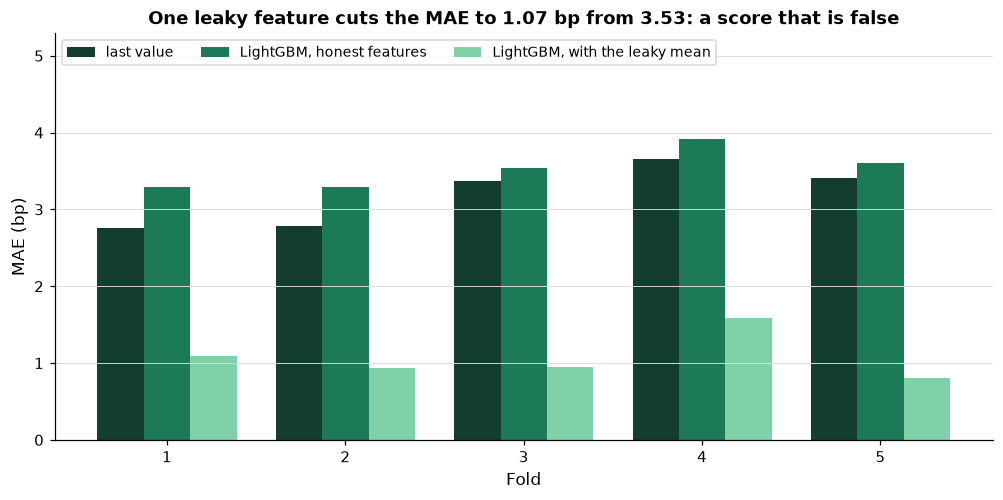

In [28]:
# the 10 Yr's MAE by fold: the last value, LightGBM on honest features, and LightGBM with one leaky feature added
fig, ax = plt.subplots(figsize=(11, 4.8))
width = 0.26
positions = leak_table.index.to_numpy()
for number, column in enumerate(leak_table.columns):
    ax.bar(positions + (number - 1) * width, leak_table[column], width, label=column)
ax.set_xlabel("Fold")
ax.set_ylabel("MAE (bp)")
ax.set_title(f"One leaky feature cuts the MAE to {leak_table.iloc[:, 2].mean():.2f} bp from {leak_table.iloc[:, 1].mean():.2f}: a score that is false")
ax.set_xticks(positions)
ax.set_ylim(0, leak_table.to_numpy().max() * 1.35)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=9, ncol=3)
plt.show()

* The honest LightGBM has a mean MAE of 3.5282 bp against the last value's 3.1937. With one leaky feature the MAE is **1.0720 bp, 34 percent of the last value's**. That is not a better model. A mean of five that includes today's change is, for a model that wants today's change, a fifth of the answer in every row, so the trees find it at once.
* **This is what a leak looks like in a result: much too good.** Nothing in the code is wrong; only the proof and the size of the improvement say so. When a model on a daily change beats the last value by more than a few percent, look for the leak before believing the result.

## 8.4 Every Setting of `LGBMRegressor`

Q. Read every setting of `LGBMRegressor`, with the defaults taken from the installed LightGBM.

In [29]:
import inspect

from lightgbm import LGBMRegressor

# every setting of LGBMRegressor, the defaults read from the installed library's constructor
lgbm_defaults = {name: p.default for name, p in inspect.signature(LGBMRegressor.__init__).parameters.items() if name not in ("self", "kwargs")}
setting_text = {
    "learning_rate": ("how much each new tree's correction counts", "higher fits faster and chases noise sooner; lower needs more trees", "yes"),
    "n_estimators": ("the number of trees, each correcting the ones before", "more trees fit more, and past some number only fit noise", "yes"),
    "num_leaves": ("the leaves of each tree: its size", "more leaves let a tree split the rows finely", "yes"),
    "min_child_samples": ("the fewest rows a leaf may hold", "higher forces every leaf to rest on more rows: a smoother model", "yes"),
    "objective": ("the loss the trees reduce: None means squared error", "'l1' reduces the absolute error, which is the MAE the course scores, and shrugs off a few huge changes", "yes"),
    "max_depth": ("a cap on a tree's depth: -1 means none", "a cap of 2 to 4 makes small trees whatever num_leaves says", "no"),
    "min_child_weight": ("the least total curvature a leaf may hold", "a second guard against thin leaves", "no"),
    "min_split_gain": ("the least gain that justifies a split", "higher grows fewer splits", "no"),
    "subsample": ("the share of rows each tree sees (needs subsample_freq above 0)", "below 1 adds randomness and some protection from noise", "no"),
    "subsample_freq": ("how often the rows are resampled: 0 never", "set to 1 to use subsample", "no"),
    "colsample_bytree": ("the share of features each tree may use", "below 1 forces trees to use different features", "no"),
    "reg_alpha": ("an L1 penalty on the leaf values", "shrinks small leaf values to zero", "no"),
    "reg_lambda": ("an L2 penalty on the leaf values", "shrinks every leaf value toward zero", "no"),
    "boosting_type": ("gbdt: ordinary gradient boosting", "dart and goss are variants the course leaves alone", "no"),
    "class_weight": ("weights for classes: only a classifier uses it", "no effect on a regressor", "no"),
    "importance_type": ("what feature_importances_ counts: splits by default", "the course reads permutation importance instead", "no"),
    "subsample_for_bin": ("rows used to find the bin edges of each feature", "higher is slower and finer", "no"),
    "n_jobs": ("threads: None means all; the course passes 1", "one thread gives the same numbers on every machine", "no"),
    "random_state": ("the seed for every random choice: None means a different one each run", "the course passes SEED", "no"),
}
assert set(setting_text) == set(lgbm_defaults), set(lgbm_defaults) ^ set(setting_text)
lgbm_settings = pd.DataFrame([(name, lgbm_defaults[name], *setting_text[name]) for name in setting_text],
                             columns=["setting", "default", "what it controls", "raising it or turning it on", "tune first"]).set_index("setting")
lgbm_settings["default"] = lgbm_settings["default"].map(repr)

plotkit.styled(lgbm_settings, [], "Every setting of LGBMRegressor: the defaults read from the installed LightGBM")

,default,what it controls,raising it or turning it on,tune first
setting,,,,
learning_rate,0.1,how much each new tree's correction counts,higher fits faster and chases noise sooner; lower needs more trees,yes
n_estimators,100,"the number of trees, each correcting the ones before","more trees fit more, and past some number only fit noise",yes
num_leaves,31,the leaves of each tree: its size,more leaves let a tree split the rows finely,yes
min_child_samples,20,the fewest rows a leaf may hold,higher forces every leaf to rest on more rows: a smoother model,yes
objective,None,the loss the trees reduce: None means squared error,"'l1' reduces the absolute error, which is the MAE the course scores, and shrugs off a few huge changes",yes
max_depth,-1,a cap on a tree's depth: -1 means none,a cap of 2 to 4 makes small trees whatever num_leaves says,no
min_child_weight,0.001,the least total curvature a leaf may hold,a second guard against thin leaves,no
min_split_gain,0.0,the least gain that justifies a split,higher grows fewer splits,no
subsample,1.0,the share of rows each tree sees (needs subsample_freq above 0),below 1 adds randomness and some protection from noise,no


* Five settings matter for a series like this, marked "tune first": `objective`, `learning_rate`, `n_estimators`, `num_leaves`, and `min_child_samples`. The rest are guards, randomness, and housekeeping, and stay at the course's values.

Q. Sweep the loss first: squared error (the default), absolute error, and Huber's blend.

In [30]:
# the loss: squared error (the default), absolute error, and Huber's blend of the two
objective_rows = []
for objective in [None, "l1", "huber"]:
    scores, _ = tskit.walk_forward_lgbm(features, target, splits, objective=objective)
    objective_rows.append({"objective": "l2 (the default)" if objective is None else objective, "mean MAE (bp)": scores["mae"].mean(),
                           "gap to the last value (bp)": scores["mae"].mean() - last_mae["10 Yr"].mean(),
                           "folds below the last value": int((scores["mae"].to_numpy() < last_mae["10 Yr"].to_numpy()).sum())})
objective_table = pd.DataFrame(objective_rows).set_index("objective")
print(objective_table.round(4).to_string())
best_label = objective_table["mean MAE (bp)"].idxmin()
best_objective = {"l2 (the default)": None, "l1": "l1", "huber": "huber"}[best_label]
print(f"lowest MAE: {best_label}")

plotkit.styled(objective_table, ["mean MAE (bp)"], "LightGBM on the 10 Yr's features by objective: five-fold MAE and the gap to the last value", higher_is_better=False, fmt="{:.4f}")

                  mean MAE (bp)  gap to the last value (bp)  folds below the last value
objective                                                                              
l2 (the default)         3.5282                      0.3345                           0
l1                       3.3508                      0.1572                           0
huber                    3.2812                      0.0876                           0
lowest MAE: huber


,mean MAE (bp),gap to the last value (bp),folds below the last value
objective,,,
l2 (the default),3.5282,0.3345,0
l1,3.3508,0.1572,0
huber,3.2812,0.0876,0


* The default squared-error loss gives a gap of +0.3345 bp: the trees chase the few huge changes, because squaring makes them dominate. The absolute-error loss, which reduces the quantity the course scores, gives +0.1572 bp, and **Huber's loss gives +0.0876 bp**: it squares small misses and counts large ones by their size, so it keeps the trees' attention on the ordinary days and off the extremes. **Match the loss to what you want the model to ignore.** Everything below uses `objective="huber"`, the lowest here.

Q. Sweep the learning rate against the number of trees, and draw the five-fold MAE less the last value's.

In [31]:
# learning rate across and number of trees down, with the objective just chosen: the five-fold MAE less the last value's
rates, trees = [0.01, 0.03, 0.1, 0.3], [25, 50, 100, 200, 400]
sweep_a = pd.DataFrame(index=pd.Index(trees, name="n_estimators"), columns=pd.Index(rates, name="learning_rate"), dtype=float)
for rate in rates:
    for count in trees:
        scores, _ = tskit.walk_forward_lgbm(features, target, splits, objective=best_objective, learning_rate=rate, n_estimators=count)
        sweep_a.loc[count, rate] = scores["mae"].mean() - last_mae["10 Yr"].mean()
best_count, best_rate = (float(v) for v in sweep_a.stack().idxmin())
best_count = int(best_count)
print(f"lowest gap to the last value {sweep_a.stack().min():.4f} bp at learning_rate {best_rate}, n_estimators {best_count}")
print(f"highest {sweep_a.stack().max():.4f} bp at the other corner; configurations below the last value: {int((sweep_a < 0).sum().sum())} of {sweep_a.size}")

lowest gap to the last value 0.0098 bp at learning_rate 0.01, n_estimators 25
highest 0.4138 bp at the other corner; configurations below the last value: 0 of 20


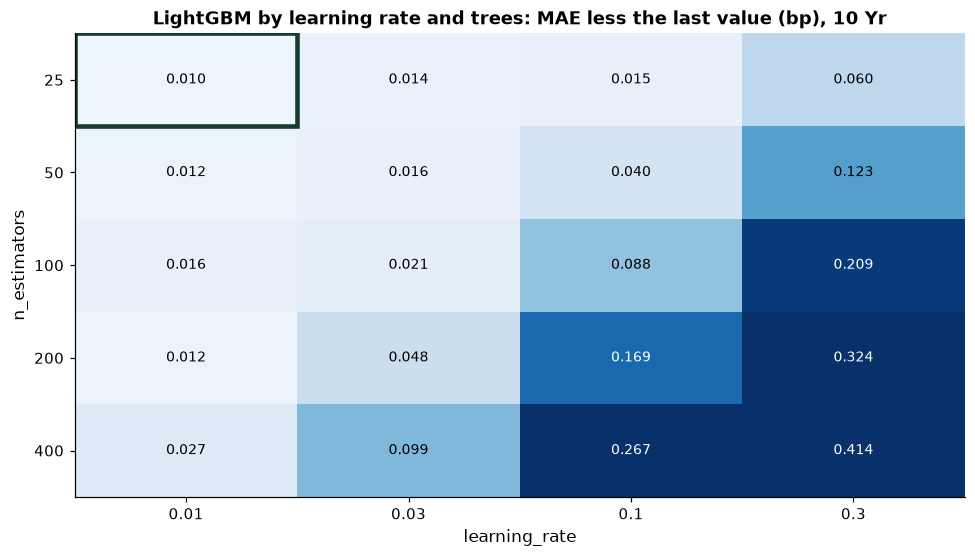

In [32]:
# the five-fold MAE less the last value's for learning_rate across and n_estimators down: below zero is closer than the last value; the lowest cell is outlined
fig, ax = plt.subplots(figsize=(9, 5.2))
matrix = sweep_a.to_numpy(dtype=float)
image = ax.imshow(matrix, cmap="Blues", aspect="auto", vmin=min(matrix.min(), 0), vmax=np.percentile(matrix, 85))
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        dark = matrix[row, column] > min(matrix.min(), 0) + 0.6 * (np.percentile(matrix, 85) - min(matrix.min(), 0))
        ax.text(column, row, f"{matrix[row, column]:.3f}", ha="center", va="center", fontsize=9, color="white" if dark else "black")
best_row, best_col = np.unravel_index(matrix.argmin(), matrix.shape)
ax.add_patch(plt.Rectangle((best_col - 0.5, best_row - 0.5), 1, 1, fill=False, edgecolor=plotkit.GREEN_DARK, linewidth=3))
ax.set_xticks(range(matrix.shape[1]), [str(v) for v in sweep_a.columns])
ax.set_yticks(range(matrix.shape[0]), [str(v) for v in sweep_a.index])
ax.set_xlabel("learning_rate")
ax.set_ylabel("n_estimators")
ax.set_title("LightGBM by learning rate and trees: MAE less the last value (bp), 10 Yr")
ax.grid(False)
fig.tight_layout()
plt.show()

* How to read it: each cell is a configuration's five-fold MAE less the last value's, in bp, so a cell below zero beats the last value. The outlined cell is the lowest, at learning_rate 0.01 and 25 trees: +0.0098 bp. The worst corner is +0.4138. **Configurations below the last value: 0 of 20.**
* **The best cell is the corner where the model does the least**: the smallest learning rate and the fewest trees, a model that has barely moved from its starting value, a constant. Every step toward more flexibility, a higher rate or more trees, raised the miss, up to +0.4138 bp. The sweep does not find a sweet spot; it finds the edge of the grid, which says the model wants to be smaller than the grid allows.

Q. Sweep the leaves against the fewest rows per leaf, at the learning rate and trees just chosen.

In [33]:
# leaves across and the fewest rows per leaf down, at the learning rate and number of trees just chosen
leaves, min_rows = [2, 4, 8, 16, 31], [5, 20, 50, 100, 200]
sweep_b = pd.DataFrame(index=pd.Index(min_rows, name="min_child_samples"), columns=pd.Index(leaves, name="num_leaves"), dtype=float)
for leaf_count in leaves:
    for rows_needed in min_rows:
        scores, _ = tskit.walk_forward_lgbm(features, target, splits, objective=best_objective, learning_rate=best_rate, n_estimators=best_count,
                                            num_leaves=leaf_count, min_child_samples=rows_needed)
        sweep_b.loc[rows_needed, leaf_count] = scores["mae"].mean() - last_mae["10 Yr"].mean()
best_rows, best_leaves = (int(v) for v in sweep_b.stack().idxmin())
print(f"lowest gap to the last value {sweep_b.stack().min():.4f} bp at num_leaves {best_leaves}, min_child_samples {best_rows}")
print(f"configurations below the last value: {int((sweep_b < 0).sum().sum())} of {sweep_b.size}")

lowest gap to the last value 0.0088 bp at num_leaves 4, min_child_samples 5
configurations below the last value: 0 of 25


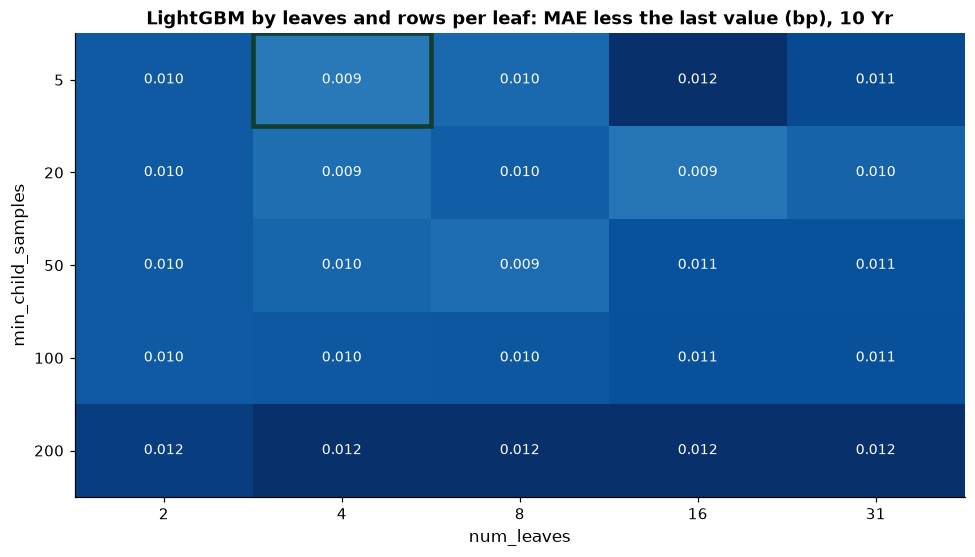

In [34]:
# the five-fold MAE less the last value's for num_leaves across and min_child_samples down: below zero is closer than the last value; the lowest cell is outlined
fig, ax = plt.subplots(figsize=(9, 5.2))
matrix = sweep_b.to_numpy(dtype=float)
image = ax.imshow(matrix, cmap="Blues", aspect="auto", vmin=min(matrix.min(), 0), vmax=np.percentile(matrix, 85))
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        dark = matrix[row, column] > min(matrix.min(), 0) + 0.6 * (np.percentile(matrix, 85) - min(matrix.min(), 0))
        ax.text(column, row, f"{matrix[row, column]:.3f}", ha="center", va="center", fontsize=9, color="white" if dark else "black")
best_row, best_col = np.unravel_index(matrix.argmin(), matrix.shape)
ax.add_patch(plt.Rectangle((best_col - 0.5, best_row - 0.5), 1, 1, fill=False, edgecolor=plotkit.GREEN_DARK, linewidth=3))
ax.set_xticks(range(matrix.shape[1]), [str(v) for v in sweep_b.columns])
ax.set_yticks(range(matrix.shape[0]), [str(v) for v in sweep_b.index])
ax.set_xlabel("num_leaves")
ax.set_ylabel("min_child_samples")
ax.set_title("LightGBM by leaves and rows per leaf: MAE less the last value (bp), 10 Yr")
ax.grid(False)
fig.tight_layout()
plt.show()

* The outlined cell is at num_leaves 4 and min_child_samples 5: +0.0088 bp, and the worst cell is +0.0125: **the whole grid spans 0.0037 bp**. At a learning rate of 0.01 with 25 trees the trees hardly matter, so the leaves and the rows per leaf hardly move the score. **Configurations below the last value: 0 of 25.** A setting that cannot move the score is not a setting worth tuning here.
* These choices were made on the same development folds that score them. That favours the chosen model, and it still does not beat the last value. A choice made on a held-out set would score no better.

Q. Write the chosen settings once.

In [35]:
# the settings chosen on the development folds, written out once
chosen = dict(objective=best_objective, learning_rate=best_rate, n_estimators=best_count, num_leaves=best_leaves, min_child_samples=best_rows)
print(f"chosen on the development folds: {chosen}")

chosen on the development folds: {'objective': 'huber', 'learning_rate': 0.01, 'n_estimators': 25, 'num_leaves': 4, 'min_child_samples': 5}


## 8.5 Scoring the Models Together

Q. Score the drift, the AR(1), simple smoothing, and LightGBM with the defaults and with the chosen settings, on three series, beside the last value.

In [36]:
def score_series(name):
    """Walk-forward MAE by fold of six rules on one series: day 2's folds on the changes (levels for the smoothing)."""
    series_changes = changes[name]
    columns = {"last value": last_mae[name].to_list()}
    for label, order in [("drift", (0, 0, 0)), ("AR(1)", (1, 0, 0))]:
        scores, _ = tskit.walk_forward_arima(series_changes, order, splits)
        columns[label] = scores["mae"].to_list()
    smooth, _ = tskit.walk_forward_smoothing(levels[name], level_splits)
    columns["simple smoothing"] = smooth["mae"].to_list()
    series_features = tskit.lag_features(changes, name, lags, windows)
    scores, _ = tskit.walk_forward_lgbm(series_features, series_changes, splits)
    columns["LightGBM, defaults"] = scores["mae"].to_list()
    scores, _ = tskit.walk_forward_lgbm(series_features, series_changes, splits, **chosen)
    columns["LightGBM, chosen"] = scores["mae"].to_list()
    return pd.DataFrame(columns, index=pd.Index(range(1, len(splits) + 1), name="fold"))


results = {name: score_series(name) for name in ["10 Yr", "2s10s", "IG"]}
score_rows = []
for name, table in results.items():
    for model in table.columns[1:]:
        score_rows.append({"series": name, "model": model, "mean MAE (bp)": table[model].mean(), "last value (bp)": table["last value"].mean(),
                           "gap to the last value (bp)": table[model].mean() - table["last value"].mean(),
                           "MASE": table[model].mean() / table["last value"].mean(),
                           "folds below the last value": int((table[model] < table["last value"]).sum()),
                           "folds of the last value, range (bp)": table["last value"].max() - table["last value"].min()})
score_table = pd.DataFrame(score_rows).set_index(["series", "model"])
print(score_table[["mean MAE (bp)", "gap to the last value (bp)", "MASE", "folds below the last value"]].round(4).to_string())

plotkit.styled(score_table, ["MASE"], "Three series: walk-forward MAE of five models against the last value carried forward, day 2's five folds",
               higher_is_better=False, fmt="{:.4f}")

                           mean MAE (bp)  gap to the last value (bp)    MASE  folds below the last value
series model                                                                                            
10 Yr  drift                      3.2012                      0.0076  1.0024                           0
       AR(1)                      3.2026                      0.0089  1.0028                           1
       simple smoothing           3.1996                      0.0059  1.0019                           3
       LightGBM, defaults         3.5282                      0.3345  1.1047                           0
       LightGBM, chosen           3.2024                      0.0088  1.0027                           0
2s10s  drift                      2.1682                      0.0134  1.0062                           0
       AR(1)                      2.1685                      0.0137  1.0064                           0
       simple smoothing           2.1683               

<styled table: Three series: walk-forward MAE of five models against the last value carried forward, day 2's five folds>

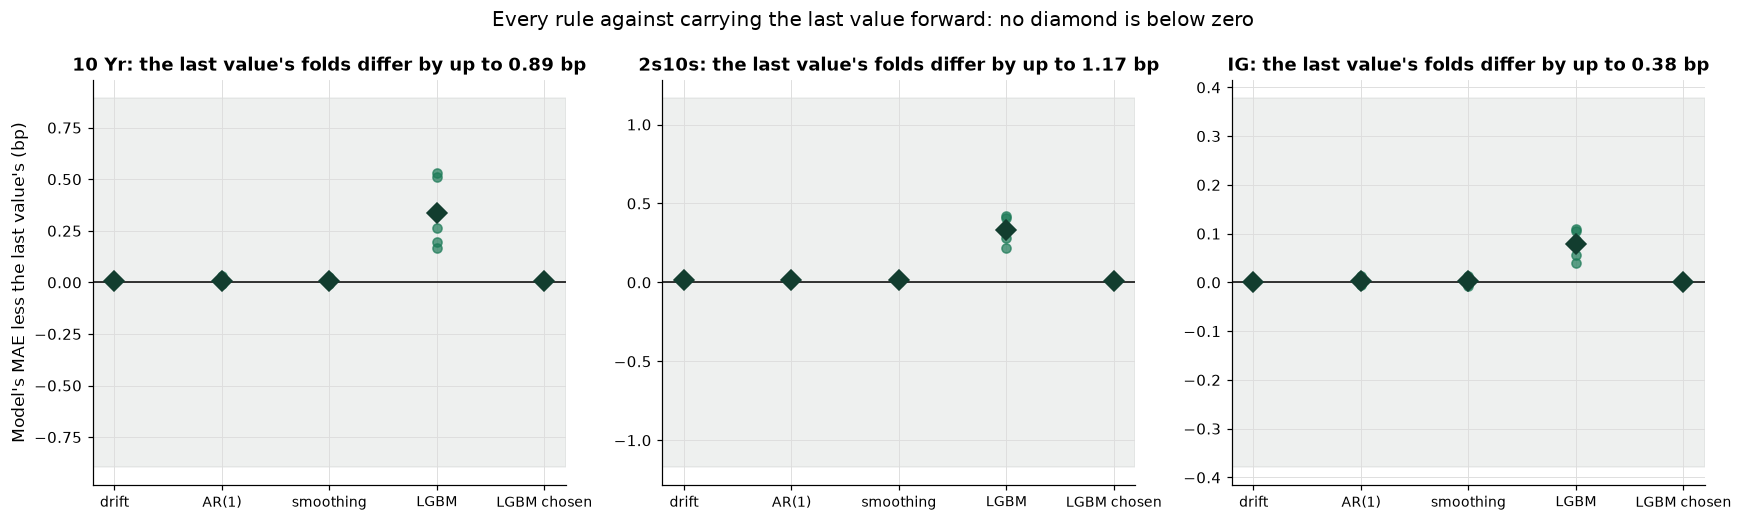

In [37]:
# three series, five rules: each dot is one fold's MAE less the last value's; diamonds are five-fold averages; the grey band is the folds' range
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, table) in zip(axes, results.items()):
    spread = table["last value"].max() - table["last value"].min()
    ax.axhspan(-spread, spread, color=plotkit.GREY, alpha=0.12)
    ax.axhline(0, color="black", linewidth=1)
    for number, column in enumerate(table.columns[1:]):
        ax.plot([number] * len(table), table[column] - table["last value"], "o", color=plotkit.GREEN, alpha=0.7)
        ax.plot([number], [table[column].mean() - table["last value"].mean()], "D", color=plotkit.GREEN_DARK, markersize=9)
    ax.set_xticks(range(5), ["drift", "AR(1)", "smoothing", "LGBM", "LGBM chosen"], fontsize=9)
    ax.set_title(f"{name}: the last value's folds differ by up to {spread:.2f} bp")
axes[0].set_ylabel("Model's MAE less the last value's (bp)")
fig.suptitle("Every rule against carrying the last value forward: no diamond is below zero")
fig.tight_layout()
plt.show()

* **No model is closer than the last value on the five-fold average**: every MASE is above 1, and the lowest is 1.0003. On the 10 Yr the last value is 3.1937 bp, the drift 3.2012, the AR(1) 3.2026, simple smoothing 3.1996, **LightGBM with the defaults 3.5282**, and LightGBM with the chosen settings 3.2024.
* **The bigger model is the worse model, and the chosen model is the smaller one.** The defaults are 10.5 percent further than the last value on the 10 Yr: 15 features and trees that can split on all of them find structure in the training rows that is not there in the test rows. The chosen settings shrink that to 0.3 percent by being barely a model: with 25 trees at a learning rate of 0.01, its values hardly leave the training average of the change, which scores like day 2's drift.
* The grey bands are how far the last value's own folds differ. Every gap sits inside them.

## 8.6 Permutation Importance, Within Folds

**How it works.** A feature is important to a fitted model if the model needs it to score well. To measure that without relying on how the model is built, **shuffle one feature's values among the test rows**, which breaks its link to the target and leaves everything else alone, give the model the shuffled table, and read how far the MAE rises. Do it five times per feature and average. A feature whose shuffling leaves the MAE unchanged is not being used. You control the number of shuffles and the score; what comes out is one number per feature per fold, in bp. It is done **within folds**, on each fold's own fitted model and test rows, so no row is used to fit a model and then to score its feature.

Q. Compute the permutation importance of every feature in every fold, for the chosen model.

In [38]:
from lightgbm import LGBMRegressor
from sklearn.inspection import permutation_importance

# permutation importance within each fold: shuffle one feature's values in the fold's test rows, and read how far the MAE rises
importance_by_fold = {}
for number, (train, test) in enumerate(splits, start=1):
    complete = features.iloc[train].notna().all(axis=1).to_numpy()
    model = LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1, **chosen).fit(features.iloc[train][complete], target.iloc[train][complete])
    result = permutation_importance(model, features.iloc[test], target.iloc[test], scoring="neg_mean_absolute_error",
                                    n_repeats=5, random_state=SEED, n_jobs=1)
    importance_by_fold[number] = pd.Series(result.importances_mean, index=features.columns)
importance = pd.DataFrame(importance_by_fold)
importance_summary = pd.DataFrame({"mean rise in MAE (bp)": importance.mean(axis=1), "spread across folds (bp)": importance.std(axis=1),
                                   "folds with a rise": (importance > 0).sum(axis=1)}).sort_values("mean rise in MAE (bp)", ascending=False)
importance_summary.index.name = "feature"
print(importance_summary.round(4).to_string())

plotkit.styled(importance_summary, ["mean rise in MAE (bp)"], "Permutation importance within folds, chosen LightGBM on the 10 Yr: the mean rise in MAE and its spread across the five folds", fmt="{:.4f}")

                   mean rise in MAE (bp)  spread across folds (bp)  folds with a rise
feature                                                                              
10 Yr lag 1                       0.0016                    0.0030                  3
10 Yr sd 5                        0.0016                    0.0018                  3
10 Yr mean 20                     0.0004                    0.0009                  1
2 Yr lag 1                        0.0004                    0.0008                  1
10 Yr lag 5                       0.0002                    0.0002                  2
10 Yr sd 20                       0.0001                    0.0003                  1
10 Yr abs mean 20                 0.0001                    0.0002                  1
10 Yr mean 5                      0.0000                    0.0000                  1
10 Yr lag 2                       0.0000                    0.0000                  0
10 Yr abs mean 5                  0.0000              

,mean rise in MAE (bp),spread across folds (bp),folds with a rise
feature,,,
10 Yr lag 1,0.0016,0.0030,3
10 Yr sd 5,0.0016,0.0018,3
10 Yr mean 20,0.0004,0.0009,1
2 Yr lag 1,0.0004,0.0008,1
10 Yr lag 5,0.0002,0.0002,2
10 Yr sd 20,0.0001,0.0003,1
10 Yr abs mean 20,0.0001,0.0002,1
10 Yr mean 5,0.0000,0.0000,1
10 Yr lag 2,0.0000,0.0000,0


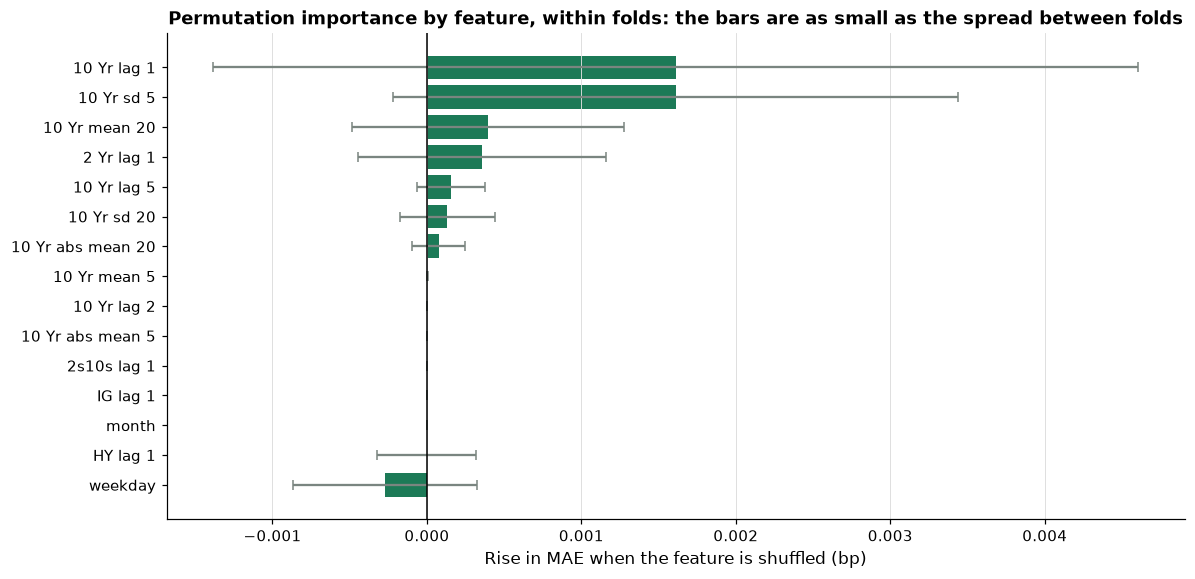

In [39]:
# the mean rise in MAE when a feature is shuffled in the test rows, with its spread across the five folds
fig, ax = plt.subplots(figsize=(11, 5.4))
ordered = importance_summary.iloc[::-1]
ax.barh(ordered.index, ordered["mean rise in MAE (bp)"], xerr=ordered["spread across folds (bp)"], color=plotkit.GREEN, ecolor=plotkit.GREY, capsize=3)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Rise in MAE when the feature is shuffled (bp)")
ax.set_title("Permutation importance by feature, within folds: the bars are as small as the spread between folds")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

* The feature with the largest mean rise is `10 Yr lag 1`: 0.0016 bp, in a model whose MAE is 3.20 bp. 8 of 15 features have a positive mean rise, and **the largest rise is under two thousandths of a bp**. The chosen model uses almost nothing, so shuffling almost anything leaves its scores alone. A model that is not closer than the last value has nothing to attribute.
* This is a limit of the method on a model with no signal, not a flaw in it. Permutation importance is worth running **after** a model has beaten its baseline. Run on a model that did not, it shows how little there is.

## 8.7 The Same Features for the Size of the Change

**How it works.** Day 7 found memory in the **size** of the change, and a GARCH, a 20-row average, and an EWMA that used it. Gradient boosting can use the same memory with no formula. The target becomes the absolute change, the features are built from the absolute changes (their lags, their windows, and the other series' sizes), and everything else is the same: shift first, prove it, and score walk-forward against the constant size. You control the same settings; what comes out is a model of how big the day's change is, and it is scored against day 7's rules on the same five folds.

Q. Build the size features, prove them, and score LightGBM beside day 7's constant size, 20-row average, and GARCH.

In [40]:
# the same features for the size of the 10 Yr's change: lags, windows, and other series' sizes, built on the absolute changes
sizes = changes.abs()
size_features = tskit.lag_features(sizes, "10 Yr", lags, windows)
size_target = sizes["10 Yr"]
tskit.assert_features_past_only(lambda frame: tskit.lag_features(frame, "10 Yr", lags, windows), sizes, proof_rows)
print(f"the size features did not move when every row from t on changed, at {len(proof_rows)} dates: True")

size_columns = {}
size_columns["constant size"] = tskit.walk_forward_score(size_target, lambda history, n_train: np.full(len(history) - n_train, history.iloc[:n_train].mean()), splits)[0]["mae"].to_list()
size_columns["20-row average"] = tskit.walk_forward_score(size_target, lambda history, n_train: history.rolling(20).mean().shift(1).iloc[n_train:].to_numpy(), splits)[0]["mae"].to_list()
size_columns["GARCH(1,1)"] = tskit.walk_forward_garch(changes["10 Yr"], splits)[0]["mae"].to_list()
size_columns["LightGBM, defaults"] = tskit.walk_forward_lgbm(size_features, size_target, splits)[0]["mae"].to_list()
size_columns["LightGBM, chosen"] = tskit.walk_forward_lgbm(size_features, size_target, splits, **chosen)[0]["mae"].to_list()
size_results = pd.DataFrame(size_columns, index=pd.Index(range(1, len(splits) + 1), name="fold"))
size_table = pd.DataFrame({"mean MAE (bp)": size_results.mean(), "ratio to the constant size": size_results.mean() / size_results["constant size"].mean(),
                           "folds below the constant": size_results.lt(size_results["constant size"], axis=0).sum()})
size_table.index.name = "rule"
print(size_table.round(4).to_string())

plotkit.styled(size_table, ["ratio to the constant size"], "The size of the 10 Yr's change: walk-forward MAE of five rules, with day 7's rules beside LightGBM", higher_is_better=False, fmt="{:.4f}")

the size features did not move when every row from t on changed, at 10 dates: True


                    mean MAE (bp)  ratio to the constant size  folds below the constant
rule                                                                                   
constant size              2.1302                      1.0000                         0
20-row average             2.0402                      0.9578                         3
GARCH(1,1)                 2.0671                      0.9704                         3
LightGBM, defaults         2.2854                      1.0729                         1
LightGBM, chosen           2.1044                      0.9879                         5


,mean MAE (bp),ratio to the constant size,folds below the constant
rule,,,
constant size,2.1302,1.0000,0
20-row average,2.0402,0.9578,3
"GARCH(1,1)",2.0671,0.9704,3
"LightGBM, defaults",2.2854,1.0729,1
"LightGBM, chosen",2.1044,0.9879,5


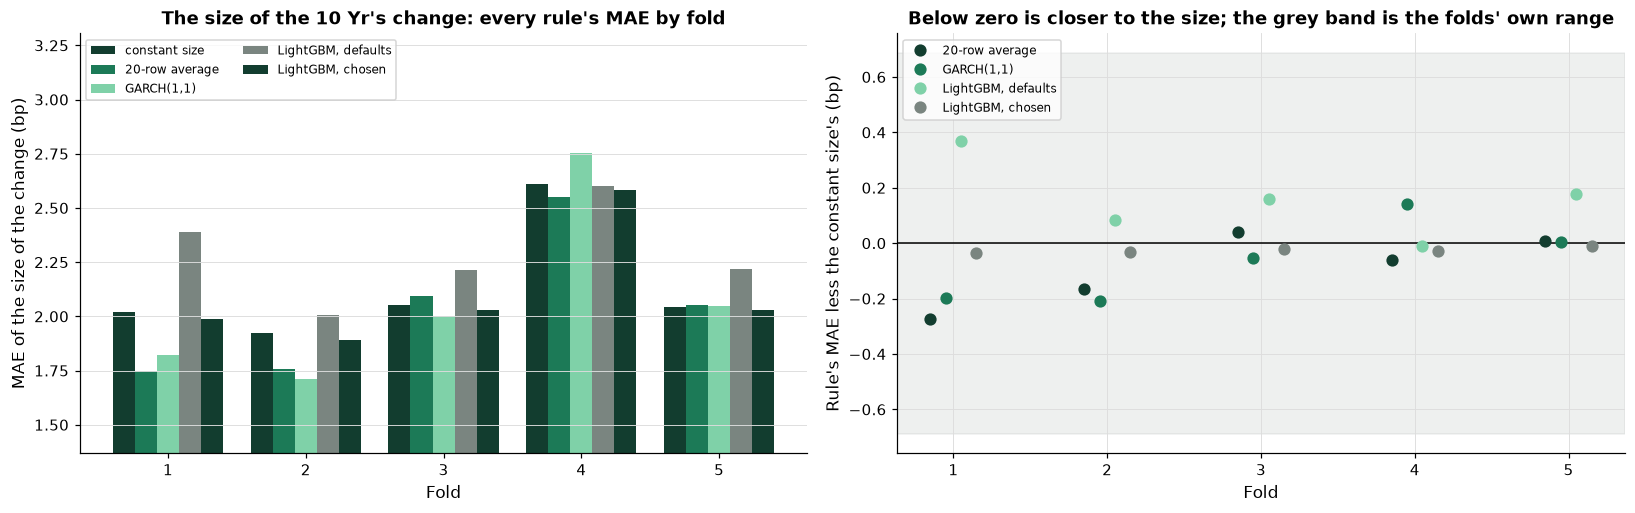

In [41]:
# the size of the 10 Yr's change: each rule's MAE by fold, and each rule's MAE less the constant size's
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 4.8))
width = 0.16
positions = size_results.index.to_numpy()
for number, column in enumerate(size_results.columns):
    left.bar(positions + (number - 2) * width, size_results[column], width, label=column)
left.set_xlabel("Fold")
left.set_ylabel("MAE of the size of the change (bp)")
left.set_title("The size of the 10 Yr's change: every rule's MAE by fold")
left.set_xticks(positions)
left.set_ylim(size_results.to_numpy().min() * 0.8, size_results.to_numpy().max() * 1.2)
left.grid(axis="x", visible=False)
left.legend(fontsize=8, loc="upper left", ncol=2)
spread = size_results["constant size"].max() - size_results["constant size"].min()
right.axhspan(-spread, spread, color=plotkit.GREY, alpha=0.12)
right.axhline(0, color="black", linewidth=1)
for number, column in enumerate(size_results.columns[1:]):
    right.plot(positions + (number - 1.5) * 0.1, size_results[column] - size_results["constant size"], "o", markersize=7, label=column)
right.set_xlabel("Fold")
right.set_ylabel("Rule's MAE less the constant size's (bp)")
right.set_title("Below zero is closer to the size; the grey band is the folds' own range")
right.set_xticks(positions)
right.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

* **The defaults fail again, and the chosen settings find a little.** LightGBM with the defaults is 7.3 percent further from the size than a constant. With the chosen settings, which were chosen for the level of the change and not retuned, it is 1.2 percent closer, a ratio of 0.9879, and below the constant on 5 of 5 folds. The 20-row average is at 0.9578 and the GARCH at 0.9704.
* **A small, patient boosted model gets less than a third of what a 20-row average gets.** The closest rule on these folds is the 20-row average. A boosted model does not beat an average of the last 20 sizes here, and it needs a proof, a seed, a loss, and a sweep to be as close as it is. When a simple rule does the job, that is the finding.
* **What this does not say.** It does not say a size model helps anyone choose a security or time anything. It describes how well rules built on earlier rows matched the changes on later dates inside this file.

## What the Models Show, and Where They Fail

**What the models show.** LightGBM on 15 lag features of the 10 Yr's change, the 2s10s, and the invented IG spread was no closer than the last value carried forward on the five-fold average, with defaults (MASE 1.1047 on the 10 Yr) and with settings chosen on the development folds (1.0027). On the size of the 10 Yr's change, the chosen settings were 1.2 percent closer than a constant size, less than day 7's GARCH (3.0 percent) and the 20-row average (4.2 percent).

**Where they fail.**

* **On the level.** More inputs and a more flexible model made the score worse, and the best of 48 configurations tried on the development folds was still above the last value.
* **On the defaults.** Squared error, 31 leaves, and 20 rows per leaf are a model for data with structure in it. On a daily change they chase the extremes.
* **On the leak.** One feature that includes the scored date made the MAE 34 percent of the last value's. Only a proof, not a score, catches it.
* **On the importances.** They rank noise on a model with nothing to find.

**What the data cannot support.** A walk-forward error on past dates describes how a model would have scored on them. It is not evidence about any later date, and nothing here was fitted for or reported at a date after 2022-12-30.

**What was not tested.** Other loss functions and learning-rate schedules, early stopping, other feature sets (longer windows, other tenors' windows), a model refitted at every date, the held-out years, which stay closed until the capstone.

## Excel Side by Side

**Excel builds every feature in this day; it does not fit the model.** A lag is a cell one row up, a rolling window is a range that ends one row up, and a calendar field is a function of the date. Each formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-21) on the 10 Yr's 2,000 development changes in bp: dates in column A, the change in B. The formulas are written for row 22, the first row with every feature (the first 20 changes are rows 2 to 21), and copied down.

<table align="left">
<tr><th align="left">Feature</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Largest gap from Python</th></tr>
<tr><td align="left">Lag 1</td><td align="left"><code>series.shift(1)</code></td><td align="left"><code>=B21</code></td><td align="left">0.0e+00</td></tr>
<tr><td align="left">Mean of the 5 rows before</td><td align="left"><code>series.shift(1).rolling(5).mean()</code></td><td align="left"><code>=AVERAGE(B17:B21)</code></td><td align="left">0.0e+00</td></tr>
<tr><td align="left">Standard deviation of the 5 rows before</td><td align="left"><code>series.shift(1).rolling(5).std()</code></td><td align="left"><code>=STDEV.S(B17:B21)</code></td><td align="left">9.1e-14</td></tr>
<tr><td align="left">Mean absolute value of the 20 rows before</td><td align="left"><code>series.shift(1).abs().rolling(20).mean()</code></td><td align="left"><code>=SUMPRODUCT(ABS(B2:B21))/20</code></td><td align="left">0.0e+00</td></tr>
<tr><td align="left">The leak: a mean of 5 that ends on the row</td><td align="left"><code>series.rolling(5).mean()</code></td><td align="left"><code>=AVERAGE(B18:B22)</code></td><td align="left">0.0e+00</td></tr>
<tr><td align="left">Weekday, Monday as 0</td><td align="left"><code>index.dayofweek</code></td><td align="left"><code>=WEEKDAY(A22,2)-1</code></td><td align="left">0.0e+00</td></tr>
<tr><td align="left">Month</td><td align="left"><code>index.month</code></td><td align="left"><code>=MONTH(A22)</code></td><td align="left">0.0e+00</td></tr>
</table>
<br clear="left">

**The leak is one row of difference.** The honest mean of five in row 22 averages the five rows that end **one row up**: `=AVERAGE(B17:B21)`. The leaky mean averages the five rows that end on the row itself: `=AVERAGE(B18:B22)`. Copy both down a column and the two columns look the same, and one of them contains the answer. The shift is nothing but where the range ends. `STDEV.S` is the sample standard deviation, which is pandas' default, and `WEEKDAY` with the second argument 2 numbers Monday as 1, so the formula subtracts 1 to match Python's Monday as 0.

**What Excel cannot do** is fit the model: no function in a cell grows boosted trees, and a features sheet is the part of this day that Excel can hold. A sheet with the features and the target is also a good way to look at the data a model sees, and to run the leak test by hand: change the row at t and look at whether the feature in that row moved.

Q. Do Excel's values equal Python's?

In [42]:
# Excel's largest gaps from Python on every feature, from the course's Excel check, beside the tolerance
gaps = pd.Series({"lag 1": 0.0, "mean of 5": 0.0, "sd of 5": 9.14823772291129e-14,
                   "abs mean of 20": 0.0, "leaky mean of 5": 0.0,
                   "weekday": 0.0, "month": 0.0}, name="largest gap")
excel_side = gaps.to_frame()
excel_side["equal within 1e-9"] = excel_side["largest gap"] < 1e-9
excel_side.index.name = "feature"
plotkit.styled(excel_side, [], "Excel beside Python on every feature, the 1,980 rows from row 22: the largest gap", fmt="{:.1e}")

,largest gap,equal within 1e-9
feature,,
lag 1,0.0e+00,True
mean of 5,0.0e+00,True
sd of 5,9.1e-14,True
abs mean of 20,0.0e+00,True
leaky mean of 5,0.0e+00,True
weekday,0.0e+00,True
month,0.0e+00,True


* Every feature is equal to within 1e-9, on every row from row 22.

## Save the Day with Git

Today's Git step is a stash. You are halfway through an experiment when something else needs the file as it was: `git stash` puts the unfinished change aside and restores the committed file, and `git stash pop` brings the change back.

Q. Start a repository in the work folder, and commit the code.

In [43]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [44]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5b_08_t5aw7_mo and nowhere else


In [45]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [46]:
!git -C "{work}" add .gitignore mlkit.py tskit.py test_tskit.py
!git -C "{work}" commit -q -m "Day 8: tskit with lag_features, assert_features_past_only, and walk_forward_lgbm"
!git -C "{work}" show --stat --format=%s HEAD

Day 8: tskit with lag_features, assert_features_past_only, and walk_forward_lgbm

 .gitignore    |   3 +
 mlkit.py      | 568 ++++++++++++++++++++++++++++++++++++++++++++++++
 test_tskit.py | 569 +++++++++++++++++++++++++++++++++++++++++++++++++
 tskit.py      | 675 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 4 files changed, 1815 insertions(+)


Q. Save the 10 Yr's LightGBM scores and commit them.

In [47]:
# the 10 Yr's walk-forward scores of the LightGBM rows as a file: 4 decimals and LF line endings
lgbm_rows = score_table.loc["10 Yr"].loc[["LightGBM, defaults", "LightGBM, chosen"], ["mean MAE (bp)", "MASE"]].round(4)
lgbm_rows.to_csv("lgbm_scores.csv", lineterminator="\n")
print((work / "lgbm_scores.csv").read_text(encoding="utf-8"))

model,mean MAE (bp),MASE
"LightGBM, defaults",3.5282,1.1047
"LightGBM, chosen",3.2024,1.0027



In [48]:
!git -C "{work}" add lgbm_scores.csv
!git -C "{work}" commit -q -m "Day 8: LightGBM scores"

Q. Start an experiment that changes the file, and stash it.

In [49]:
# an experiment, in the middle of the work: the file is changed to try a wider setting
lgbm_rows.assign(note="wider grid, unfinished").to_csv("lgbm_scores.csv", lineterminator="\n")

In [50]:
# stash push puts the change aside under a name; the empty status after it says the file is as committed
!git -C "{work}" status --short
!git -C "{work}" stash push -m "wider grid, unfinished"
!git -C "{work}" status --short
!git -C "{work}" stash list

 M lgbm_scores.csv
?? course3_synthetic_spreads.csv
?? plotkit.py
?? treasury_par_yields.csv


Saved working directory and index state On main: wider grid, unfinished


?? course3_synthetic_spreads.csv
?? plotkit.py
?? treasury_par_yields.csv


stash@{0}: On main: wider grid, unfinished


Q. The urgent work is done. Bring the experiment back.

In [51]:
# pop applies the stashed change and removes it from the list; -q keeps its message short
!git -C "{work}" stash pop -q
!git -C "{work}" status --short
!git -C "{work}" stash list

 M lgbm_scores.csv
?? course3_synthetic_spreads.csv
?? plotkit.py
?? treasury_par_yields.csv


* The stash held the unfinished change while the file was clean, and `pop` put it back and emptied the list. A stash is not a commit: it is a place for work that is not ready to be one, and it is local to this repository.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `tskit.py` and paste the code of today's three `tskit.py` cells (sections 8.1, 8.2, and 8.3) at the end, without their first lines. Do the same for the three `test_tskit.py` cells in `test_tskit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_tskit.py
```

The last line says `46 passed`.

**Step 4.** Commit.

```powershell
git add tskit.py test_tskit.py
git commit -m "Day 8: tskit with lag_features, assert_features_past_only, and walk_forward_lgbm"
```

## You Can Now

* Build lag features with shift first and roll second, and draw which rows feed each one.
* Prove with `assert_features_past_only` that no feature uses its own date, and recognise a leak by a score that is far too good.
* Score LightGBM walk-forward (`walk_forward_lgbm`) against the last value, the drift, the AR(1), and smoothing.
* Read every setting of `LGBMRegressor`, choose the loss, and sweep the learning rate, the trees, the leaves, and the rows per leaf.
* Read permutation importance within folds, and say what it shows on a model with nothing to find.
* Say plainly what was found: LightGBM on lags was no closer than the last value (MASE 1.1047 with the defaults, 1.0027 chosen, on the 10 Yr), and on the size of the change the chosen settings were 1.2 percent closer than a constant, less than a 20-row average.

Next, week 2, day 4: two series together, cointegration and the half-life of a gap between them.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the five series, makes day 2's five folds (`changes`, `splits`, `last_mae`), the features of the 10 Yr's change (`lags`, `windows`), and defines `check`, a small function that marks your answers.

In [52]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# five series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "2 Yr": (development["2 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "2s10s": ((development["10 Yr"] - development["2 Yr"]) * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"five series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5, used by every later day: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252
# day 2's folds on the levels, and on the changes (one row later: each fold's positions shift down by one)
changes = levels.diff().dropna()
level_splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
splits = [(train[1:] - 1, test - 1) for train, test in level_splits]
for number, (train, test) in enumerate(splits, start=1):
    mlkit.assert_past_only(changes.index[train], changes.index[test])
    print(f"fold {number}: fit on {len(train)} changes to {changes.index[train[-1]].date()}, "
          f"score {len(test)} from {changes.index[test[0]].date()} to {changes.index[test[-1]].date()}")

# the last value carried forward is a change of zero: its miss is the size of the change (day 5's baseline)
last_mae = pd.DataFrame({column: [changes[column].iloc[test].abs().mean() for _, test in splits] for column in changes.columns},
                        index=pd.Index(range(1, len(splits) + 1), name="fold"))
print(last_mae.mean().round(4).to_string())
lags, windows = [1, 2, 5], [5, 20]


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
five series in bp: ['2 Yr', '10 Yr', '2s10s', 'IG', 'HY']; blank cells: 0
fold 1: fit on 503 changes to 2017-01-05, score 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 755 changes to 2018-01-08, score 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1007 changes to 2019-01-11, score 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1259 changes to 2020-01-15, score 252 from 2020-01-16 to 2021-01-19
fold 5: fit on 1511 changes to 2021-01-19, score 252 from 2021-01-20 to 2022-01-19
2 Yr     2.1881
10 Yr    3.1937
2s10s    2.1548
IG       0.8017
HY       3.5018


### Exercise 1

Q. Build `tskit.lag_features(changes, "IG", [1, 3], [10])` and store the number of rows that have a missing feature in **ex1_missing**. Why that many?

In [53]:
ex1_missing = ...

In [54]:
check("Exercise 1 rows with a missing feature", ex1_missing, 10)

Exercise 1 rows with a missing feature: not attempted yet


### Exercise 2

Q. Add a function to your module. `past_rolling_mean(series, window)` returns the mean of the `window` rows before each date, not including the date. It refuses a window below 2 with `ValueError`. Write the docstring first. Add `test_past_rolling_mean_ends_the_row_before`, which checks a value, the leading NaN rows, that `tskit.assert_features_past_only` passes on it, and the refusal (use the test file's `lag_frame`). Run pytest, reload the module, and store its value for the last date of the 2 Yr's changes with a window of 10, rounded to 4 decimals, in **ex2_mean**.

Write the function in the cell that starts with `%%writefile -a tskit.py` and the test in the one that starts with `%%writefile -a test_tskit.py`, and run each of those cells once.

In [55]:
%%writefile -a tskit.py


# Exercise 2: write past_rolling_mean(series, window) below this line

Appending to tskit.py


In [56]:
%%writefile -a test_tskit.py


# Exercise 2: write test_past_rolling_mean_ends_the_row_before() below this line

Appending to test_tskit.py


In [57]:
# run pytest, reload the module, then use your function on the 2 Yr's changes
ex2_mean = ...

In [58]:
check("Exercise 2 mean of the 10 changes before the last date, 2 Yr", ex2_mean, 1.1)

Exercise 2 mean of the 10 changes before the last date, 2 Yr: not attempted yet


### Exercise 3

Q. Score LightGBM with the library's settings on the invented HY spread's changes: build its features with `tskit.lag_features(changes, "HY", lags, windows)`, score with `tskit.walk_forward_lgbm(features, changes["HY"], splits)`, and store the ratio of its five-fold average MAE to the last value's (`last_mae["HY"].mean()`), rounded to 3 decimals, in **ex3_mase**. Is it above or below 1?

In [59]:
ex3_mase = ...

In [60]:
check("Exercise 3 MASE of LightGBM, HY", ex3_mase, 1.075)

Exercise 3 MASE of LightGBM, HY: not attempted yet


### Exercise 4

Q. Show a leak on the 2s10s. Build its features, add `changes["2s10s"].rolling(5).mean()` as a column called `leak`, score LightGBM with `tskit.walk_forward_lgbm`, and store the five-fold average MAE, rounded to 3 decimals, in **ex4_mae**. Compare it with the last value's `last_mae["2s10s"].mean()`: is it believable?

In [61]:
ex4_mae = ...

In [62]:
check("Exercise 4 MAE with the leak, 2s10s", ex4_mae, 0.684)

Exercise 4 MAE with the leak, 2s10s: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that returns rolling features of a series of daily changes, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The mean and the standard deviation of the `window` values before each date, as features for scoring that date.

    series is a dated Series of daily changes in bp. window is a whole number of 2 or more.
    Returns a DataFrame with the columns "mean" and "std" on the same dates, where the row for a date uses only the
    `window` rows before that date (the first `window` rows are NaN).
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a DataFrame, and contains one bug.

In [63]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def rolling_features(series, window=5):
    """The mean and the standard deviation of the `window` values before each date, as features for scoring that date.

    series is a dated Series of daily changes in bp. window is a whole number of 2 or more.
    Returns a DataFrame with the columns "mean" and "std" on the same dates, where the row for a date uses only the
    `window` rows before that date (the first `window` rows are NaN).
    """
    # one rolling pass over the series gives both statistics
    return series.rolling(window).agg(["mean", "std"])

Q. Before you run the test: for a date t, which rows does this function's mean use? Read the docstring, then the code.

Q. Test the function against its docstring before you trust it.

In [64]:
# the test, written from the docstring before the code is trusted
rng = np.random.default_rng(SEED)
frame = pd.DataFrame({"x": rng.standard_normal(400)}, index=pd.bdate_range("2020-01-01", periods=400))
try:
    tskit.assert_features_past_only(lambda f: rolling_features(f["x"], 5), frame, [100, 300])
except AssertionError as error:
    raise AssertionError(str(error)) from None
print("no feature uses its own date")

AssertionError: the feature 'mean' dated 2020-05-20 changed when the rows from 2020-05-20 on changed, so it uses a row that is not before its date

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's standard deviation for the last date of the test frame, rounded to 3 decimals, in **ex5_sd**.

In [65]:
# fix the function above and run the test again, then store the answer
ex5_sd = ...

In [66]:
check("Exercise 5 standard deviation of the 5 rows before the last date", ex5_sd, 0.278)

Exercise 5 standard deviation of the 5 rows before the last date: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```